# EDA Deep-Dive: Portscan Dataset

**Goal**: Understand the data structure, feature relationships, per-node behavior, class separability, and establish a non-temporal baseline.

**Use case**: Real-time anomaly detection for a dashboard. The system must detect **whether a port scan is occurring** and **which node(s) are affected**, with minimal latency.

**Label semantics**:
- 0 = Normal Traffic
- 1 = Horizontal Scan (same port across many IPs)
- 2 = Vertical Scan (many ports on same IP)
- 5 = Distributed / Spillover Scan (low-and-slow, multi-source)

**Per-node anomaly detection reformulation**: For the dashboard, we need to know **per observer node** whether scanning activity is present. This reframes the problem:
- Instead of a single 4-class prediction per timestep, we need **per-node binary or multi-class outputs**
- The model must identify which specific node(s) are under scan at each moment
- Classes 1 and 2 are only present on `isp_private0`; other nodes only have 0 (Normal) and 5 (Distributed/Spillover)
- This means **node-specific models or a multi-output architecture** should be considered

### Dataset Context

This dataset captures network traffic from **4 ISP-level observer nodes** over approximately **4.4 days** (~380K seconds).
Each row represents a 10-second aggregated observation window with 48 engineered features plus a `scan_label` target.

**Key characteristics:**
- Two scenarios are mixed: `training_congestion` and `training_portscan` — the model must distinguish scanning behavior **even during congestion events**
- 4 observer nodes represent different network positions: FTTH gateway, two mobile gateways, and a private gateway
- All features are pre-computed per-timestep — no raw packet data
- No missing values in the dataset

**Why this matters for LSTM modeling:** The temporal sequence structure (observations every 10s per node) is the core reason we use an LSTM. The sliding window approach (current `SEQ_LEN=16`) covers 160 seconds of network activity per prediction.

**Real-time inference pipeline:**
- Every 10 seconds, new observations arrive for all 4 nodes
- The model takes the last N timesteps (window) and predicts: is a scan active? Which node(s)?
- **Latency = window_duration + inference_time**. A 160s window means the first prediction arrives 160s after deployment.
- Shorter windows detect faster but with less context; longer windows are more accurate but slower to alert
- **Key trade-off**: detection speed vs. accuracy — we will analyze this below

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings("ignore")

try:
    import xgboost as xgb
    XGB_AVAILABLE = True
except ImportError:
    XGB_AVAILABLE = False
    print("XGBoost not installed — skipping feature importance baseline.")

In [2]:
OUT_DIR = Path("images")
OUT_DIR.mkdir(exist_ok=True)

LABEL_NAMES = {0: "Normal", 1: "Horizontal", 2: "Vertical", 5: "Distributed/Spillover"}
CLASS_ORDER = [0, 1, 2, 5]
PALETTE = {0: "#2ecc71", 1: "#e74c3c", 2: "#f39c12", 5: "#3498db"}

---
## Phase 1: Data Profile

Load the dataset, inspect shape, missing values, class distribution, and per-node breakdown.

In [3]:
print("=" * 70)
print("PHASE 1: DATA PROFILE")
print("=" * 70)

file_id = "1lYT9J7ZAo4MdTqN-RHqBja8OVins-Nv8"
df = pd.read_csv(f"https://drive.google.com/uc?id={file_id}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Missing values: {df.isna().sum().sum()}")

cat_cols = df.select_dtypes(include="object").columns.tolist()
num_cols_all = df.select_dtypes(include=np.number).columns.tolist()
num_cols_all = [c for c in num_cols_all if c != "scan_label"]
print(f"\nCategorical cols ({len(cat_cols)}): {cat_cols}")
print(f"Numerical cols ({len(num_cols_all)}): {len(num_cols_all)}")

PHASE 1: DATA PROFILE
Shape: 115,260 rows × 50 columns
Missing values: 0

Categorical cols (2): ['observer_node', 'scenario']
Numerical cols (47): 47



--- scan_label distribution ---
  0 (Normal              ): 11,547  (10.02%)
  1 (Horizontal          ):  1,267  ( 1.10%)
  2 (Vertical            ): 17,195  (14.92%)
  5 (Distributed/Spillover): 85,251  (73.96%)


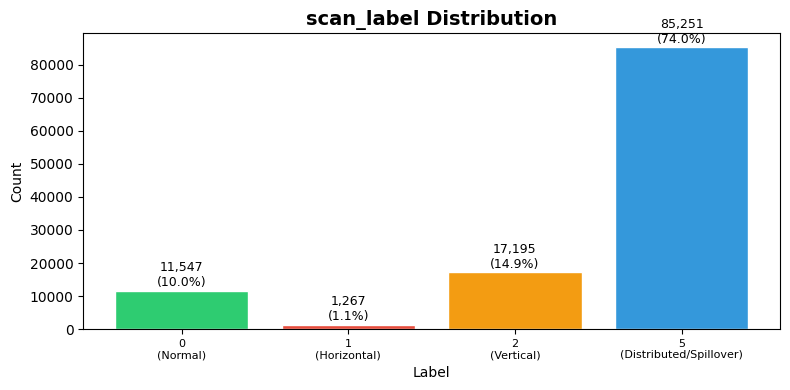

In [7]:
print("\n--- scan_label distribution ---")
vc = df["scan_label"].value_counts().sort_index()
for k in CLASS_ORDER:
    cnt = vc.get(k, 0)
    print(f"  {k} ({LABEL_NAMES[k]:20s}): {cnt:>6,}  ({cnt/len(df)*100:5.2f}%)")

fig, ax = plt.subplots(figsize=(8, 4))
colors = [PALETTE[k] for k in CLASS_ORDER]
bars = ax.bar(
    [str(k) for k in CLASS_ORDER],
	[vc.get(k, 0) for k in CLASS_ORDER],
	color=colors, edgecolor="white"
)
for bar_obj, cnt in zip(bars, [vc.get(k, 0) for k in CLASS_ORDER]):
    ax.text(bar_obj.get_x() + bar_obj.get_width()/2, bar_obj.get_height() + 500,
            f"{cnt:,}\n({cnt/len(df)*100:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_title("scan_label Distribution", fontsize=14, fontweight="bold")
ax.set_ylabel("Count")
ax.set_xlabel("Label")
ax.set_xticklabels([f"{k}\n({LABEL_NAMES[k]})" for k in CLASS_ORDER], fontsize=8)
plt.tight_layout()
fig.savefig(OUT_DIR / "class_distribution.png", dpi=150)
plt.show()

In [8]:
print("\n--- observer_node summary ---")
print(df["observer_node"].value_counts())
print(f"\n--- scenario summary ---")
print(df["scenario"].value_counts())


--- observer_node summary ---
observer_node
isp_private0.private.gateway    83169
isp_mobile1.mobile.gateway      13853
isp_mobile0.mobile.gateway      13681
isp_ftth0.ftth.gateway           4557
Name: count, dtype: int64

--- scenario summary ---
scenario
training_congestion    84226
training_portscan      31034
Name: count, dtype: int64


### Why Class Imbalance Matters

The label distribution reveals a **severe class imbalance**:
- **Class 5 (Distributed/Spillover)** dominates at 74% — this is low-and-slow scanning that looks very similar to normal background noise
- **Class 1 (Horizontal Scan)** has only **1,267 samples (1.1%)** — 67x fewer than class 5

**Impact on LSTM training:**
- Standard CrossEntropyLoss will be dominated by class 5, producing a model that predicts "Distributed/Spillover" for everything and still achieves 74% accuracy
- The rare Horizontal scans (class 1) are the most dangerous in practice (same port hammering across many IPs) yet hardest to learn
- **Mitigations needed:** (a) Class weights in loss function, (b) Focal Loss to focus on hard examples, (c) Oversampling minority classes in each batch

**Per-node roles:** Note that `isp_private0` has 72% of all data (83K rows), while `isp_ftth0` has only 4,557 rows (4%). This imbalance means the model will naturally learn patterns that favor `isp_private0`'s behavior.

---
## Phase 2: Correlation Analysis

Find highly correlated feature pairs (|r| > 0.95) and visualize relationships within feature groups.

In [6]:
print("\n" + "=" * 70)
print("PHASE 2: CORRELATION ANALYSIS")
print("=" * 70)

# Check for constant / near-constant features
const_feats = []
num_cols = num_cols_all.copy()
for c in num_cols_all:
    s = df[c].std()
    n = df[c].nunique()
    if np.isnan(s) or s < 1e-10 or n <= 1:
        const_feats.append(c)
        print(f"  Near-constant: {c:30s}  std={s:.6e}  nunique={n}")
if const_feats:
    print(f"\nNear-constant features ({len(const_feats)}): {const_feats}")
else:
    print("\nNo near-constant features detected.")
num_cols = [c for c in num_cols if c not in const_feats]
print(f"Remaining numerical features: {len(num_cols)}")


PHASE 2: CORRELATION ANALYSIS
  Near-constant: total_synack                    std=0.000000e+00  nunique=1
  Near-constant: total_ack                       std=0.000000e+00  nunique=1
  Near-constant: unique_src_ips                  std=0.000000e+00  nunique=1
  Near-constant: unique_dst_ips                  std=0.000000e+00  nunique=1
  Near-constant: unique_dst_ports                std=0.000000e+00  nunique=1
  Near-constant: payload_bytes                   std=0.000000e+00  nunique=1
  Near-constant: scanning_src_count              std=0.000000e+00  nunique=1
  Near-constant: scan_breadth                    std=0.000000e+00  nunique=1
  Near-constant: scan_entropy_proxy              std=0.000000e+00  nunique=1

Near-constant features (9): ['total_synack', 'total_ack', 'unique_src_ips', 'unique_dst_ips', 'unique_dst_ports', 'payload_bytes', 'scanning_src_count', 'scan_breadth', 'scan_entropy_proxy']
Remaining numerical features: 38


In [7]:
corr = df[num_cols].corr(method="pearson")

# Find high-correlation pairs
triu = np.triu(np.ones(corr.shape), k=1).astype(bool)
high_pairs = []
for i, j in zip(*np.where(triu & (np.abs(corr.values) > 0.95))):
    high_pairs.append((corr.index[i], corr.columns[j], corr.values[i, j]))

print(f"\nFeature pairs with |r| > 0.95 ({len(high_pairs)} pairs):")
if high_pairs:
    for a, b, r_val in sorted(high_pairs, key=lambda x: -abs(x[2]))[:20]:
        print(f"  {a:25s}  <->  {b:25s}  r = {r_val:+.4f}")
    print(f"  ... and {len(high_pairs) - 20} more")


Feature pairs with |r| > 0.95 (81 pairs):
  conn_success_pct           <->  conn_failure_rate          r = -0.9973
  conn_success_pct           <->  rst_per_syn                r = -0.9973
  conn_success_pct           <->  failed_per_syn             r = -0.9973
  total_rst                  <->  failed_conns               r = +0.9970
  conn_failure_rate          <->  rst_per_syn                r = +0.9968
  rst_per_syn                <->  failed_per_syn             r = +0.9968
  conn_failure_rate          <->  failed_per_syn             r = +0.9968
  failed_conns               <->  scan_intensity             r = +0.9968
  total_rst                  <->  scan_intensity             r = +0.9968
  tcp_ctrl_bytes             <->  total_tcp_ctrl             r = +0.9962
  lb_syn_60s                 <->  lb_dst_ip_60s              r = +0.9958
  lb_dst_ip_60s              <->  lb_dst_port_60s            r = +0.9957
  lb_syn_60s                 <->  lb_dst_port_60s            r = +0.9957
  syn_bu

### Interpreting the 9 Near-Constant Features

These 9 features have **zero variance** (a single value throughout the entire dataset). This means they provide **zero discriminative information** and should be dropped from the LSTM:

| Feature | Constant Value | Why It's Constant |
|---|---|---|
| `total_synack`, `total_ack` | 0 | Port scans use half-open SYNs; TCP handshake never completes |
| `unique_src_ips`, `unique_dst_ips`, `unique_dst_ports` | 0 | These dispersion features are computed only during active scan windows, not per-window |
| `payload_bytes` | 0 | Port scans rarely carry payload data |
| `scanning_src_count`, `scan_breadth`, `scan_entropy_proxy` | 0 | These are summary statistics computed at dataset creation time, not per-timestep features |

**Action:** Remove these 9 columns from the feature set before training. The current `lstm_pipeline.py` passes them through the LSTM, adding noise and unnecessary parameters.

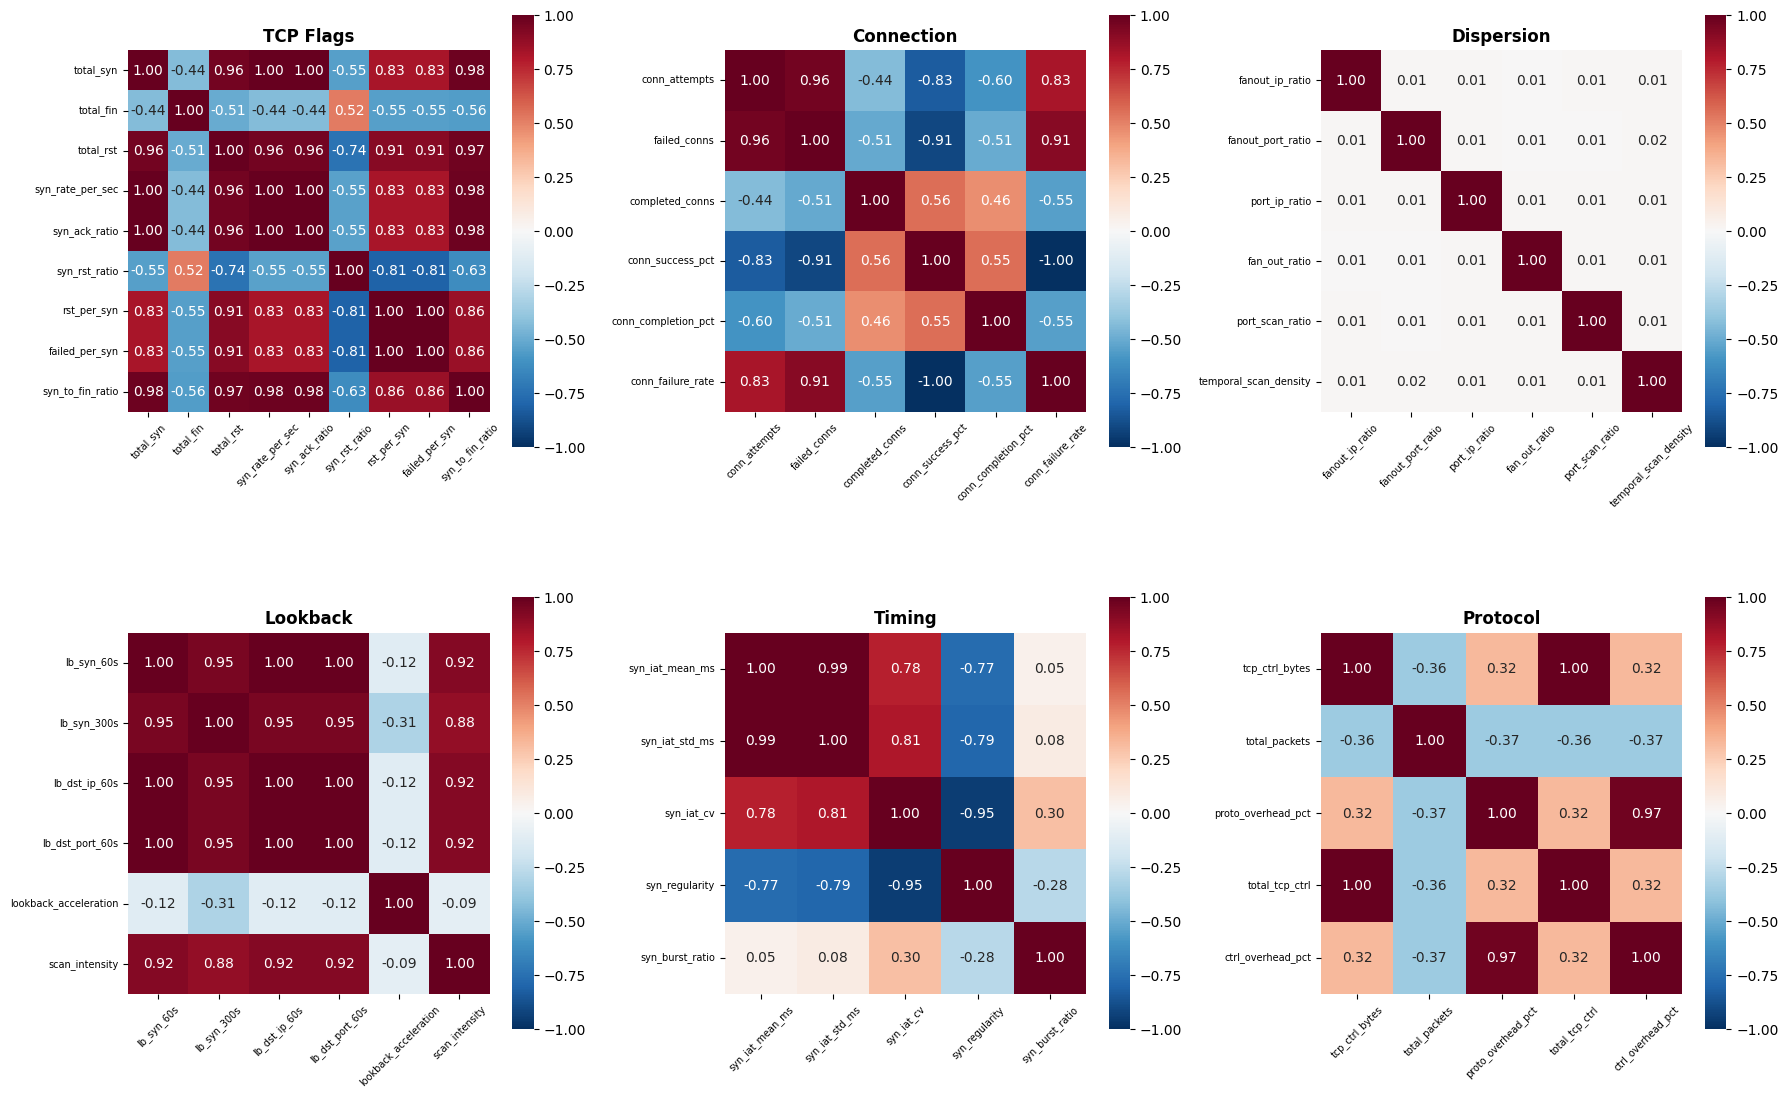

In [8]:
# Feature grouping
groups = {
    "TCP Flags": ["total_syn", "total_synack", "total_ack", "total_fin", "total_rst",
                  "syn_rate_per_sec", "syn_ack_ratio", "syn_rst_ratio",
                  "rst_per_syn", "failed_per_syn", "syn_to_fin_ratio"],
    "Connection": ["conn_attempts", "failed_conns", "completed_conns",
                   "conn_success_pct", "conn_completion_pct", "conn_failure_rate"],
    "Dispersion": ["unique_src_ips", "unique_dst_ips", "unique_dst_ports",
                   "fanout_ip_ratio", "fanout_port_ratio", "port_ip_ratio",
                   "scan_breadth", "scan_entropy_proxy", "fan_out_ratio",
                   "port_scan_ratio", "temporal_scan_density"],
    "Lookback": ["lb_syn_60s", "lb_syn_300s", "lb_dst_ip_60s", "lb_dst_port_60s",
                 "lookback_acceleration", "scan_intensity"],
    "Timing": ["syn_iat_mean_ms", "syn_iat_std_ms", "syn_iat_cv",
               "syn_regularity", "syn_burst_ratio"],
    "Protocol": ["tcp_ctrl_bytes", "payload_bytes", "total_packets",
                 "proto_overhead_pct", "total_tcp_ctrl", "ctrl_overhead_pct",
                 "scanning_src_count"],
}
available_groups = {}
for gname, feats in groups.items():
    avail = [f for f in feats if f in num_cols]
    if avail:
        available_groups[gname] = avail

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
for idx, (gname, feats) in enumerate(available_groups.items()):
    if idx >= 6:
        break
    gcorr = df[feats].corr().replace([np.inf, -np.inf], np.nan).fillna(0)
    sns.heatmap(gcorr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                vmin=-1, vmax=1, square=True, ax=axes[idx],
                cbar_kws={"shrink": 0.8})
    axes[idx].set_title(gname, fontweight="bold")
    axes[idx].tick_params(axis="x", rotation=45, labelsize=7)
    axes[idx].tick_params(axis="y", rotation=0, labelsize=7)
for idx in range(len(available_groups), 6):
    axes[idx].set_visible(False)
plt.tight_layout()
fig.savefig(OUT_DIR / "group_correlations.png", dpi=150)
plt.show()

### Feature Redundancy: 81 Highly Correlated Pairs

The 81 feature pairs with |r| > 0.95 reveal **massive multicollinearity**. This means many features are near-perfect linear combinations of others:

**Redundancy groups (keep 1 per group):**
- **Group 1 (Scan volume)**: `total_syn ≈ conn_attempts ≈ syn_rate_per_sec ≈ syn_ack_ratio` (all r > 0.995) → **Keep**: `total_syn` (most interpretable)
- **Group 2 (Failed connections)**: `failed_conns ≈ total_rst ≈ scan_intensity` (all r > 0.996) → **Keep**: `failed_conns`
- **Group 3 (Failure rate)**: `conn_failure_rate ≈ rst_per_syn ≈ failed_per_syn ≈ conn_success_pct * (-1)` (all |r| > 0.996) → **Keep**: `conn_failure_rate`
- **Group 4 (Lookback)**: `lb_syn_60s ≈ lb_dst_ip_60s ≈ lb_dst_port_60s` (all r > 0.995) → **Keep**: `lb_syn_60s`
- **Group 5 (Timing)**: `syn_iat_mean_ms ≈ syn_iat_std_ms` (r = 0.994) → **Keep**: `syn_iat_mean_ms`
- **Group 6 (Protocol)**: `proto_overhead_pct ≈ ctrl_overhead_pct` (r = 0.973) → **Keep**: `proto_overhead_pct`

**Why prune?** Multicollinearity doesn't break LSTMs the way it breaks linear regression, but it:
1. Increases parameter count unnecessarily (LSTM gates scale with feature count)
2. Slows convergence (model must learn redundant weights)
3. Provides no additional signal

PCA confirms: **11 components capture 95% of the variance** — so 38 original features compress ~3.5x without meaningful information loss.

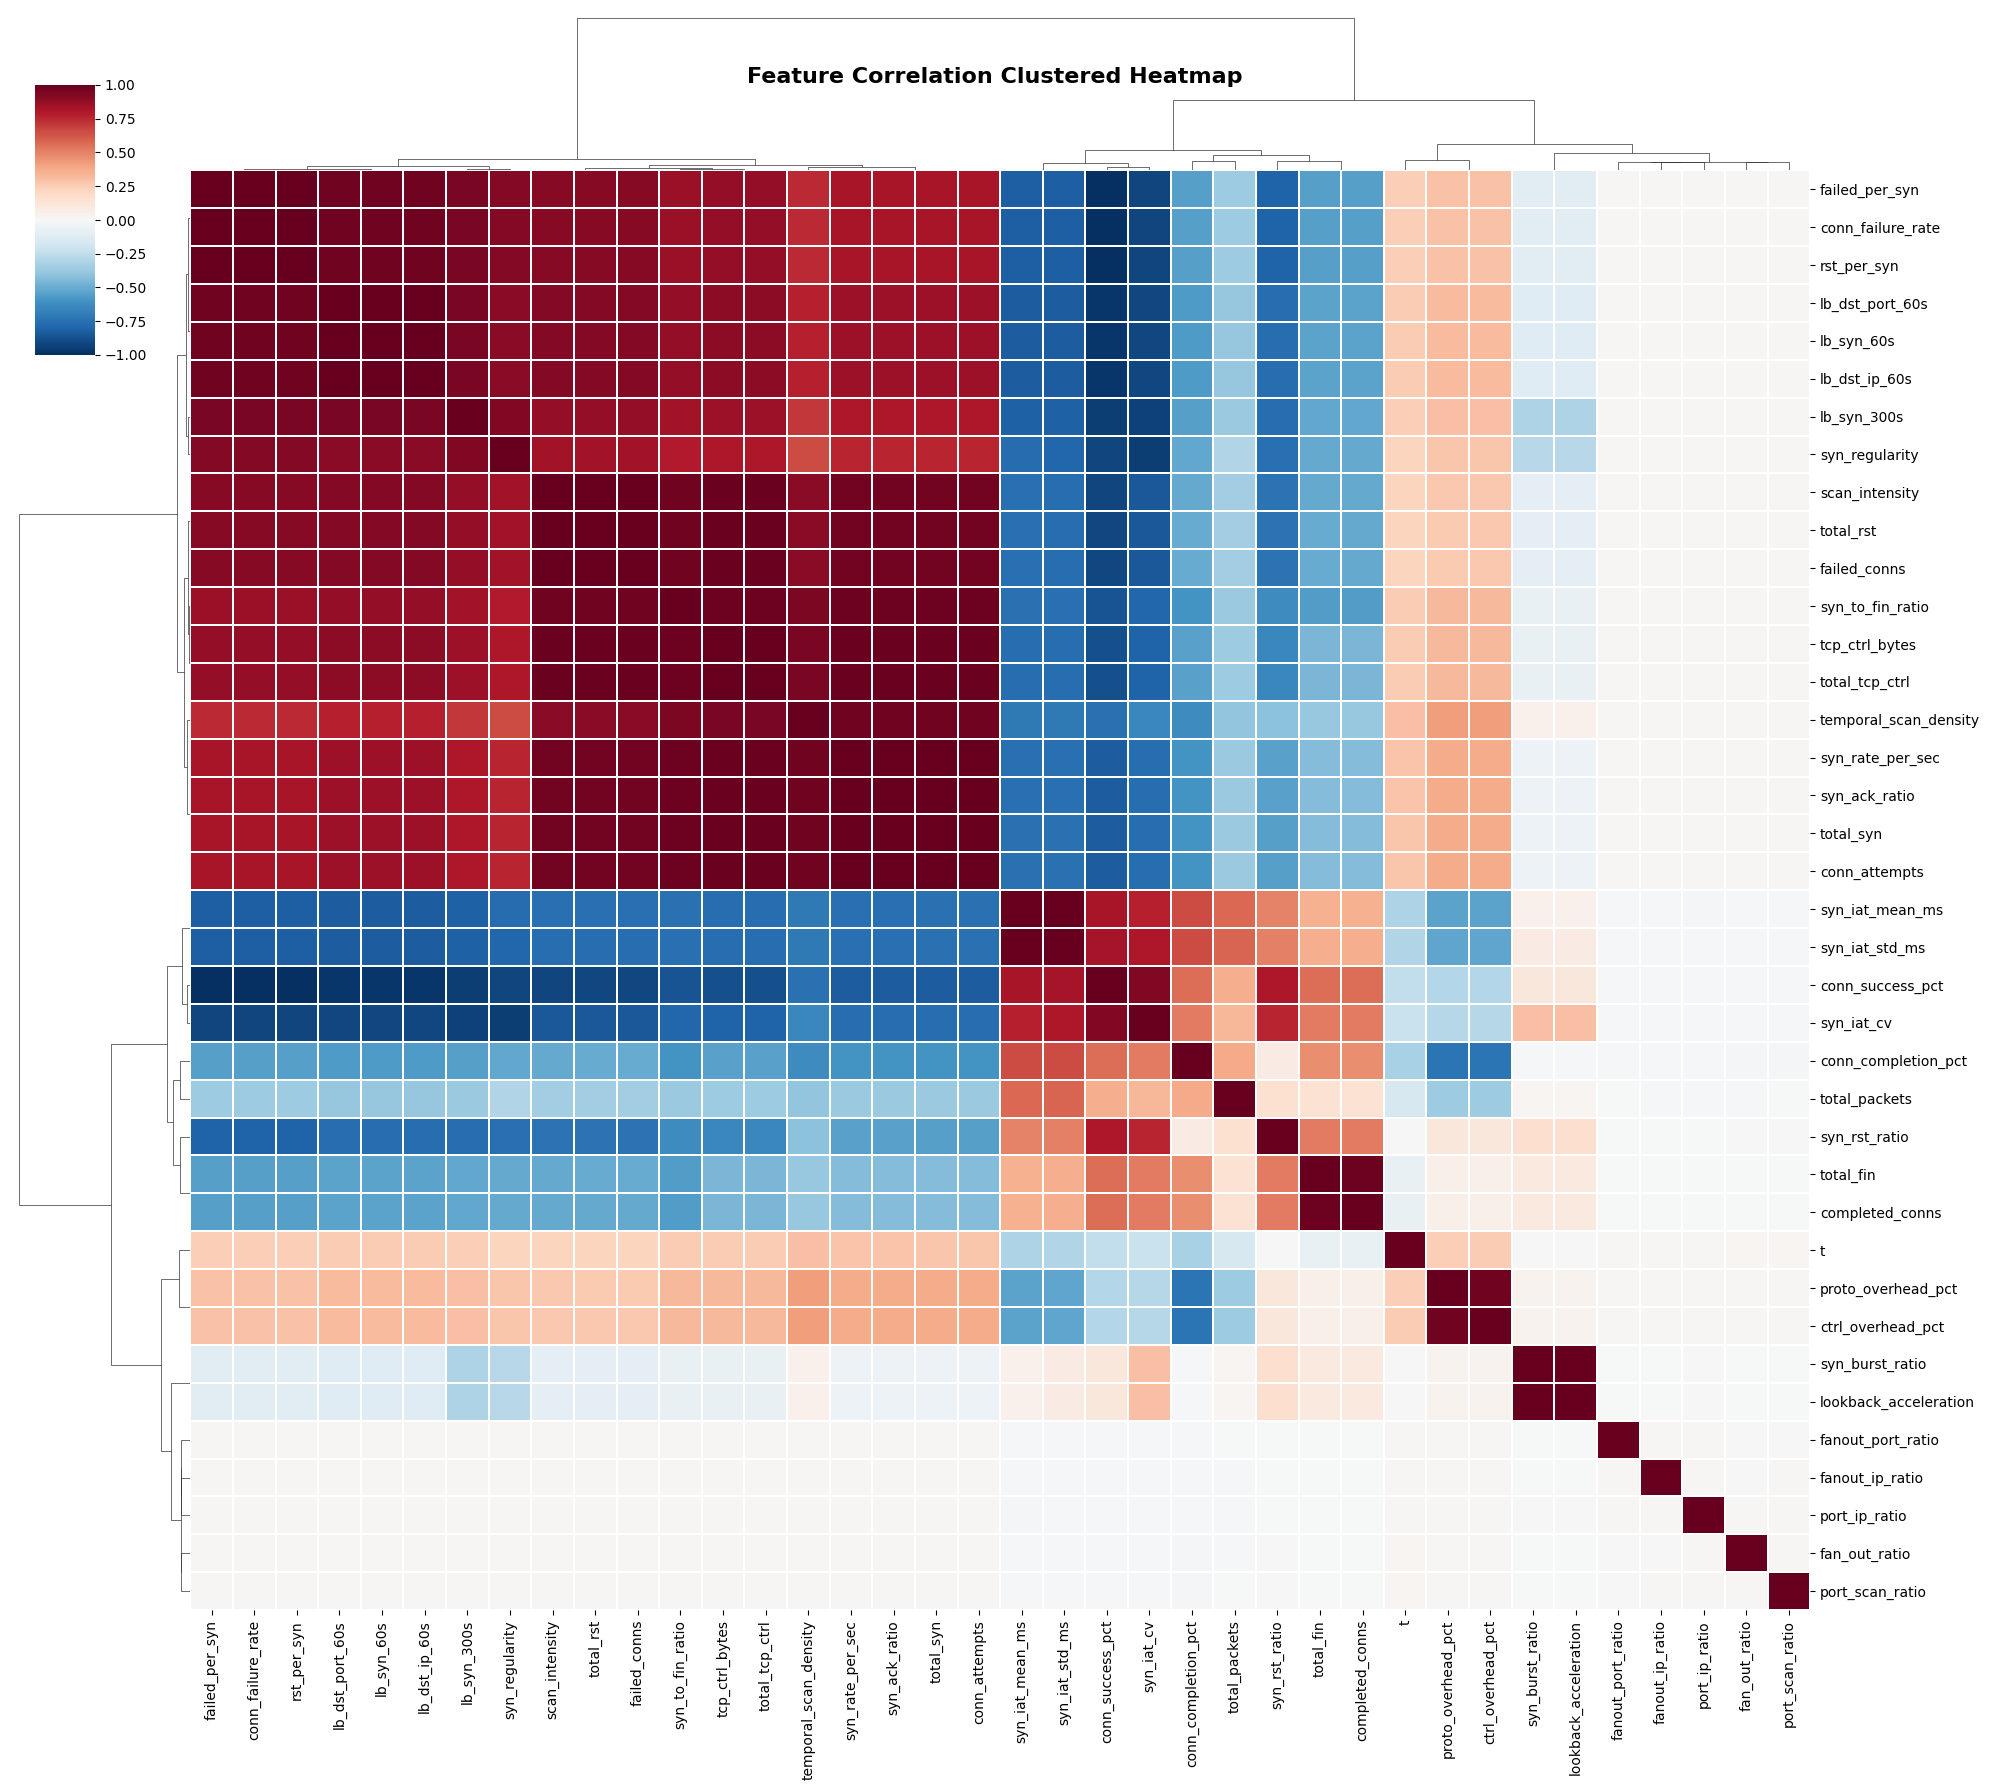

In [13]:
# Full clustered heatmap
corr_clean = corr.dropna(axis=0, how="all").dropna(axis=1, how="all")
corr_clean = corr_clean.loc[corr_clean.index.isin(corr_clean.columns), corr_clean.columns]
corr_clean = corr_clean.replace([np.inf, -np.inf], np.nan).fillna(0)
non_const = corr_clean.columns[corr_clean.std() > 1e-10]
corr_clean = corr_clean.loc[non_const, non_const]

try:
    cg = sns.clustermap(corr_clean, method="ward", cmap="RdBu_r", center=0,
                        vmin=-1, vmax=1, linewidths=0.3,
                        figsize=(20, 18), dendrogram_ratio=0.1,
                        cbar_pos=(0.02, 0.8, 0.03, 0.15))
    cg.fig.suptitle("Feature Correlation Clustered Heatmap", fontsize=16, fontweight="bold", y=0.96)
    cg.savefig(OUT_DIR / "correlation_clustered_heatmap.png", dpi=150)
    plt.show()
except Exception as e:
    print(f"Clustermap failed: {e}")
    fig, ax = plt.subplots(figsize=(16, 14))
    sns.heatmap(corr_clean, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                square=True, ax=ax, cbar_kws={"shrink": 0.8})
    ax.set_title("Feature Correlation Heatmap", fontweight="bold")
    ax.tick_params(axis="x", rotation=90, labelsize=6)
    ax.tick_params(axis="y", rotation=0, labelsize=6)
    plt.tight_layout()
    fig.savefig(OUT_DIR / "correlation_heatmap_fallback.png", dpi=150)
    plt.show()

---
## Phase 3: Per-Node Analysis

Check how label distributions and feature patterns vary across the 4 observer nodes.

In [9]:
print("\n" + "=" * 70)
print("PHASE 3: PER-NODE ANALYSIS")
print("=" * 70)

nodes = df["observer_node"].unique()
print(f"Total nodes: {len(nodes)}")
for node in sorted(nodes):
    ndf = df[df["observer_node"] == node]
    vc_node = ndf["scan_label"].value_counts().sort_index()
    print(f"\n  {node}:")
    print(f"    Samples: {len(ndf):,}")
    print(f"    Time range: {ndf['t'].min():.0f} \u2013 {ndf['t'].max():.0f}")
    for k in CLASS_ORDER:
        cnt = vc_node.get(k, 0)
        print(f"      Label {k} ({LABEL_NAMES[k]:20s}): {cnt:>6,}  ({cnt/len(ndf)*100:5.2f}%)")


PHASE 3: PER-NODE ANALYSIS
Total nodes: 4

  isp_ftth0.ftth.gateway:
    Samples: 4,557
    Time range: 70 – 378690
      Label 0 (Normal              ):  4,014  (88.08%)
      Label 1 (Horizontal          ):      0  ( 0.00%)
      Label 2 (Vertical            ):      0  ( 0.00%)
      Label 5 (Distributed/Spillover):    543  (11.92%)

  isp_mobile0.mobile.gateway:
    Samples: 13,681
    Time range: 70 – 380080
      Label 0 (Normal              ):  3,726  (27.23%)
      Label 1 (Horizontal          ):      0  ( 0.00%)
      Label 2 (Vertical            ):      0  ( 0.00%)
      Label 5 (Distributed/Spillover):  9,955  (72.77%)

  isp_mobile1.mobile.gateway:
    Samples: 13,853
    Time range: 70 – 380070
      Label 0 (Normal              ):  3,717  (26.83%)
      Label 1 (Horizontal          ):      0  ( 0.00%)
      Label 2 (Vertical            ):      0  ( 0.00%)
      Label 5 (Distributed/Spillover): 10,136  (73.17%)

  isp_private0.private.gateway:
    Samples: 83,169
    Time 

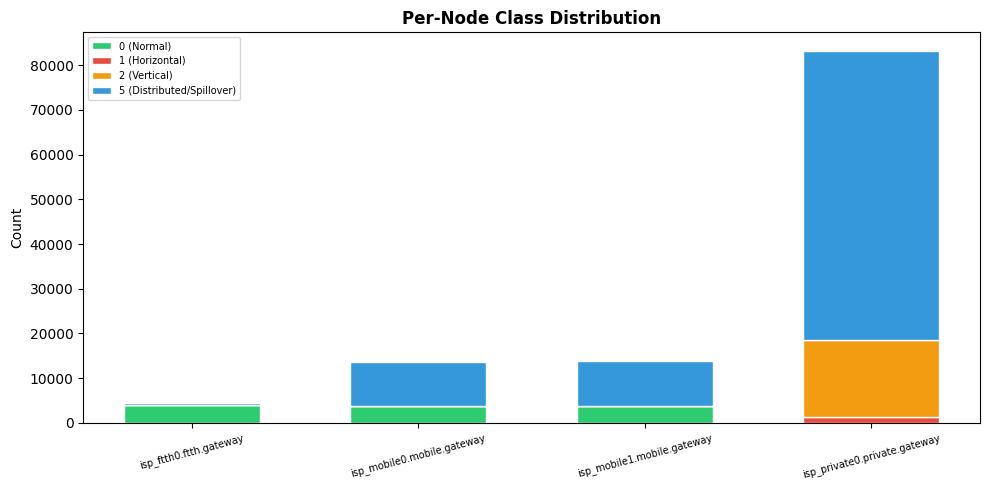

In [10]:
# Per-node stacked bar
fig, ax = plt.subplots(figsize=(10, 5))
node_order = sorted(nodes)
node_counts = {n: [] for n in node_order}
for n in node_order:
    ndf = df[df["observer_node"] == n]
    for k in CLASS_ORDER:
        node_counts[n].append((ndf["scan_label"] == k).sum())

bottom = np.zeros(len(node_order))
for i, k in enumerate(CLASS_ORDER):
    vals = [node_counts[n][i] for n in node_order]
    ax.bar(node_order, vals, bottom=bottom, label=f"{k} ({LABEL_NAMES[k]})",
           color=PALETTE[k], edgecolor="white", width=0.6)
    bottom += vals
ax.set_title("Per-Node Class Distribution", fontweight="bold")
ax.set_ylabel("Count")
ax.legend(fontsize=7)
ax.tick_params(axis="x", rotation=15, labelsize=7)
plt.tight_layout()
fig.savefig(OUT_DIR / "per_node_distribution.png", dpi=150)
plt.show()

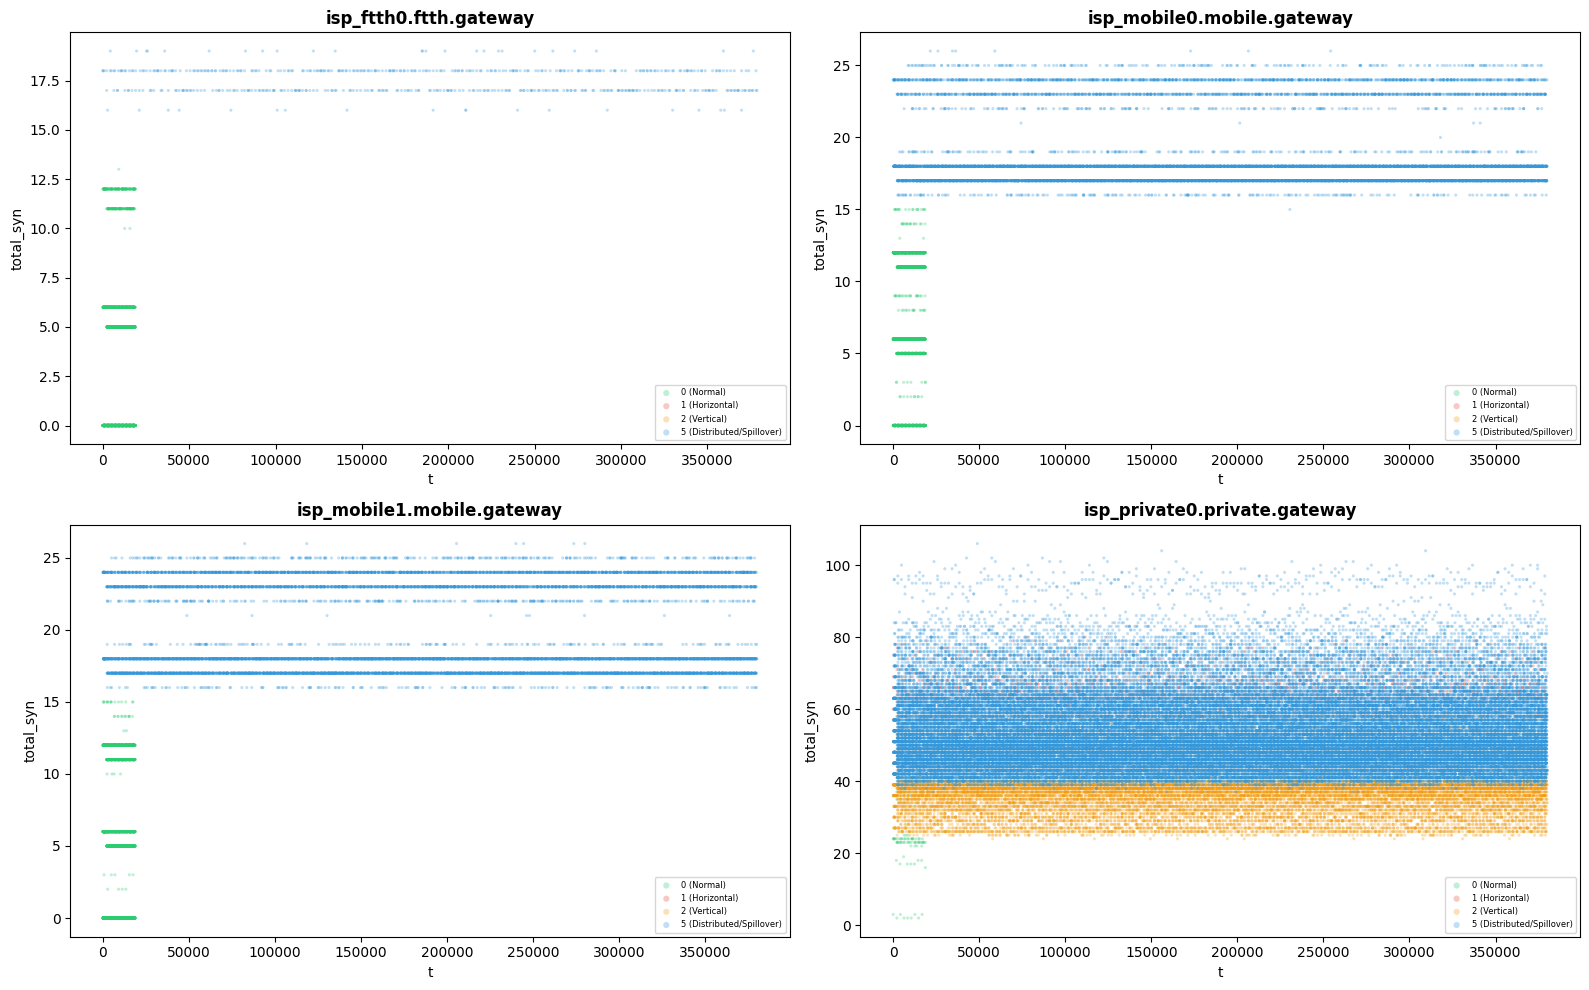

In [17]:
# Per-node temporal scatter
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()
for idx, node in enumerate(sorted(nodes)):
    ndf = df[df["observer_node"] == node]
    ax = axes[idx]
    for k in CLASS_ORDER:
        sub = ndf[ndf["scan_label"] == k]
        ax.scatter(sub["t"], sub["total_syn"], c=PALETTE[k], label=f"{k} ({LABEL_NAMES[k]})",
                   alpha=0.3, s=5, edgecolors="none")
    ax.set_title(node, fontweight="bold")
    ax.set_xlabel("t")
    ax.set_ylabel("total_syn")
    ax.legend(fontsize=6, markerscale=2)
plt.tight_layout()
fig.savefig(OUT_DIR / "per_node_temporal.png", dpi=150)
plt.show()

### Critical Finding: Node-Dependent Label Distribution

This is one of the most important discoveries of this EDA:

| Node | Labels Present | Notes |
|---|---|---|
| `isp_private0` | **0, 1, 2, 5** | The **only** node with Horizontal (1) and Vertical (2) scans |
| `isp_ftth0` | 0, 5 only | 88% Normal — mostly clean traffic |
| `isp_mobile0` | 0, 5 only | 73% Distributed/Spillover |
| `isp_mobile1` | 0, 5 only | 73% Distributed/Spillover |

**Problem for the current pipeline:** The chronological train/val/test split per `observer_node` means:
- If the val/test time windows for `isp_private0` happen to contain few or no class 1 samples, those splits will have **zero examples** of the rarest class
- The model will never be evaluated on its ability to detect Horizontal scans
- Conversely, a model trained only on `isp_ftth0`/mobile nodes would never see classes 1 or 2

**Recommendations:**
1. **Stratified split**: Ensure each split (train/val/test) preserves per-node class proportions
2. **Per-node evaluation**: Report metrics separately for each node to check generalization
3. **Node embedding**: Add an embedding layer for `observer_node` so the LSTM can learn node-specific behavior patterns
4. **Separate models per node**: Train distinct models for `isp_private0` vs. the mobile/FTTH group

---
## Phase 4: Dimensionality Reduction (PCA & t-SNE)

Understand how many dimensions capture the data's variance and visualize class separability.

In [11]:
print("\n" + "=" * 70)
print("PHASE 4: DIMENSIONALITY REDUCTION")
print("=" * 70)

# Subsample for t-SNE
MAX_TSNE = 25000
if len(df) > MAX_TSNE:
    sss = StratifiedShuffleSplit(n_splits=1, test_size=MAX_TSNE / len(df), random_state=42)
    idx, _ = next(sss.split(df, df["scan_label"]))
    tsne_idx = np.random.RandomState(42).choice(idx, size=min(MAX_TSNE, len(idx)), replace=False)
    tsne_df = df.iloc[tsne_idx].reset_index(drop=True)
else:
    tsne_df = df.copy()

print(f"t-SNE subsample: {len(tsne_df):,} rows")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[num_cols])
X_tsne_scaled = scaler.transform(tsne_df[num_cols])


PHASE 4: DIMENSIONALITY REDUCTION
t-SNE subsample: 25,000 rows



PCA components for 95% variance: 11
Top 5 explained variance ratios: [0.59119616 0.0797817  0.05517956 0.03997223 0.03303514]


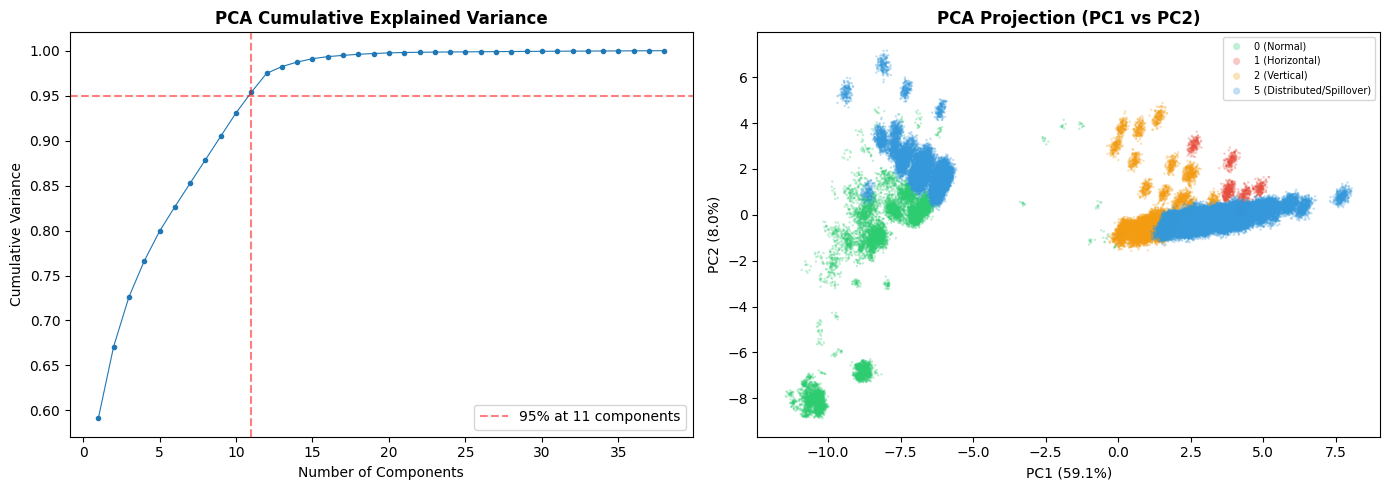


Top 5 features for PC1: {'scan_intensity': 0.20492496096284302, 'failed_conns': 0.20486489812295836, 'total_rst': 0.20484386814617703, 'lb_dst_ip_60s': 0.20397525597818666, 'lb_syn_60s': 0.20396486848340933}
Top 5 features for PC2: {'proto_overhead_pct': 0.45363007159885727, 'ctrl_overhead_pct': 0.45357588883317534, 'syn_rst_ratio': 0.3104560327108886, 'conn_completion_pct': 0.28180505111925813, 'syn_burst_ratio': 0.23246025105635382}


In [12]:
# PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)
cum_var = np.cumsum(pca.explained_variance_ratio_)
n95 = np.argmax(cum_var >= 0.95) + 1
print(f"\nPCA components for 95% variance: {n95}")
print(f"Top 5 explained variance ratios: {pca.explained_variance_ratio_[:5]}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, len(cum_var) + 1), cum_var, marker=".", linewidth=0.8)
axes[0].axhline(0.95, color="red", linestyle="--", alpha=0.5)
axes[0].axvline(n95, color="red", linestyle="--", alpha=0.5, label=f"95% at {n95} components")
axes[0].set_title("PCA Cumulative Explained Variance", fontweight="bold")
axes[0].set_xlabel("Number of Components")
axes[0].set_ylabel("Cumulative Variance")
axes[0].legend()

for k in CLASS_ORDER:
    mask = df["scan_label"] == k
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], c=PALETTE[k],
                    label=f"{k} ({LABEL_NAMES[k]})", alpha=0.3, s=3, edgecolors="none")
axes[1].set_title("PCA Projection (PC1 vs PC2)", fontweight="bold")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[1].legend(fontsize=7, markerscale=3)
plt.tight_layout()
fig.savefig(OUT_DIR / "pca_projection.png", dpi=150)
plt.show()

# Top PC loadings
pc1_loadings = pd.Series(pca.components_[0], index=num_cols).abs().sort_values(ascending=False)
pc2_loadings = pd.Series(pca.components_[1], index=num_cols).abs().sort_values(ascending=False)
print(f"\nTop 5 features for PC1: {pc1_loadings.head(5).to_dict()}")
print(f"Top 5 features for PC2: {pc2_loadings.head(5).to_dict()}")

### PCA Interpretation

**11 components capture 95% of the variance** — massive dimensionality reduction potential.

**PC1 (59.1% of variance) — "Scan Intensity Axis":**
Top loadings: `scan_intensity`, `failed_conns`, `total_rst`, `lb_dst_ip_60s`, `lb_syn_60s`
This axis separates normal traffic (low values) from active scanning (high values). All 5 top features are near-perfectly correlated, forming a single "scan burst" signal.

**PC2 (8.0% of variance) — "Protocol Overhead Axis":**
Top loadings: `proto_overhead_pct`, `ctrl_overhead_pct`, `syn_rst_ratio`, `conn_completion_pct`, `syn_burst_ratio`
This axis captures protocol-level efficiency — high values indicate many control packets relative to data, characteristic of scanning probes.

**Implication for LSTM:** Reducing from 38 features to ~11 (via PCA projection or feature selection) would shrink LSTM parameter count by ~3.5x, speeding up training without meaningful information loss.

### t-SNE Observations

The t-SNE projections colored by label show **partial but incomplete class separation**:
- Classes 1 (Horizontal), 2 (Vertical), and 5 (Distributed) overlap significantly — they share a common "scan subspace" and aren't cleanly separable in 2D
- Class 0 (Normal) forms a tighter cluster but still overlaps with class 5 at boundaries
- The **scenario split** (congestion vs. portscan) shows two distinct clusters — this is concerning because `scenario` might be leaking label information
- Coloring by observer node shows strong node-specific clustering, confirming node ID is a critical feature



Running t-SNE perplexity=30...


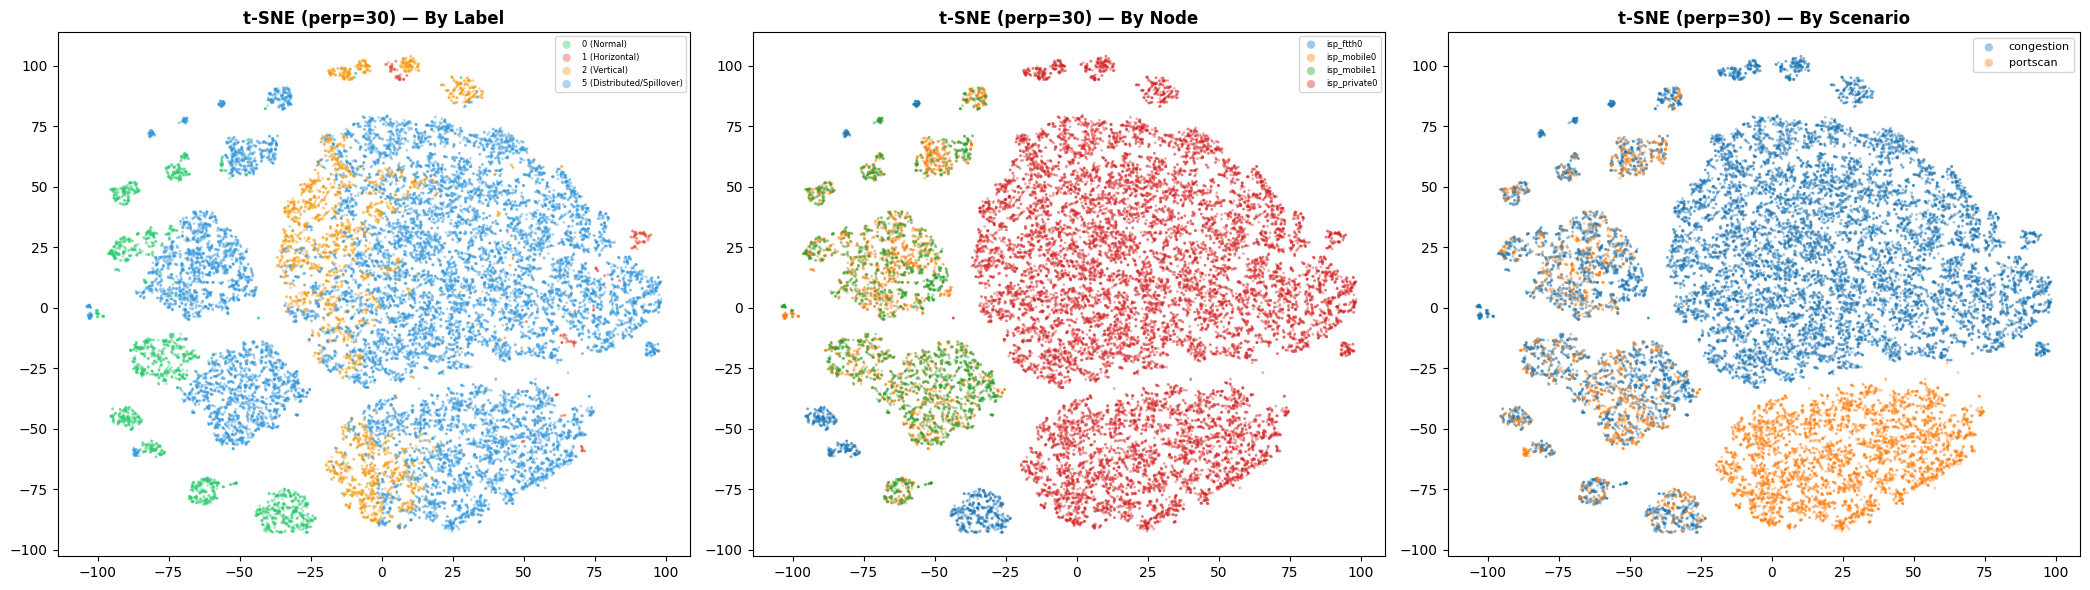


Running t-SNE perplexity=50...


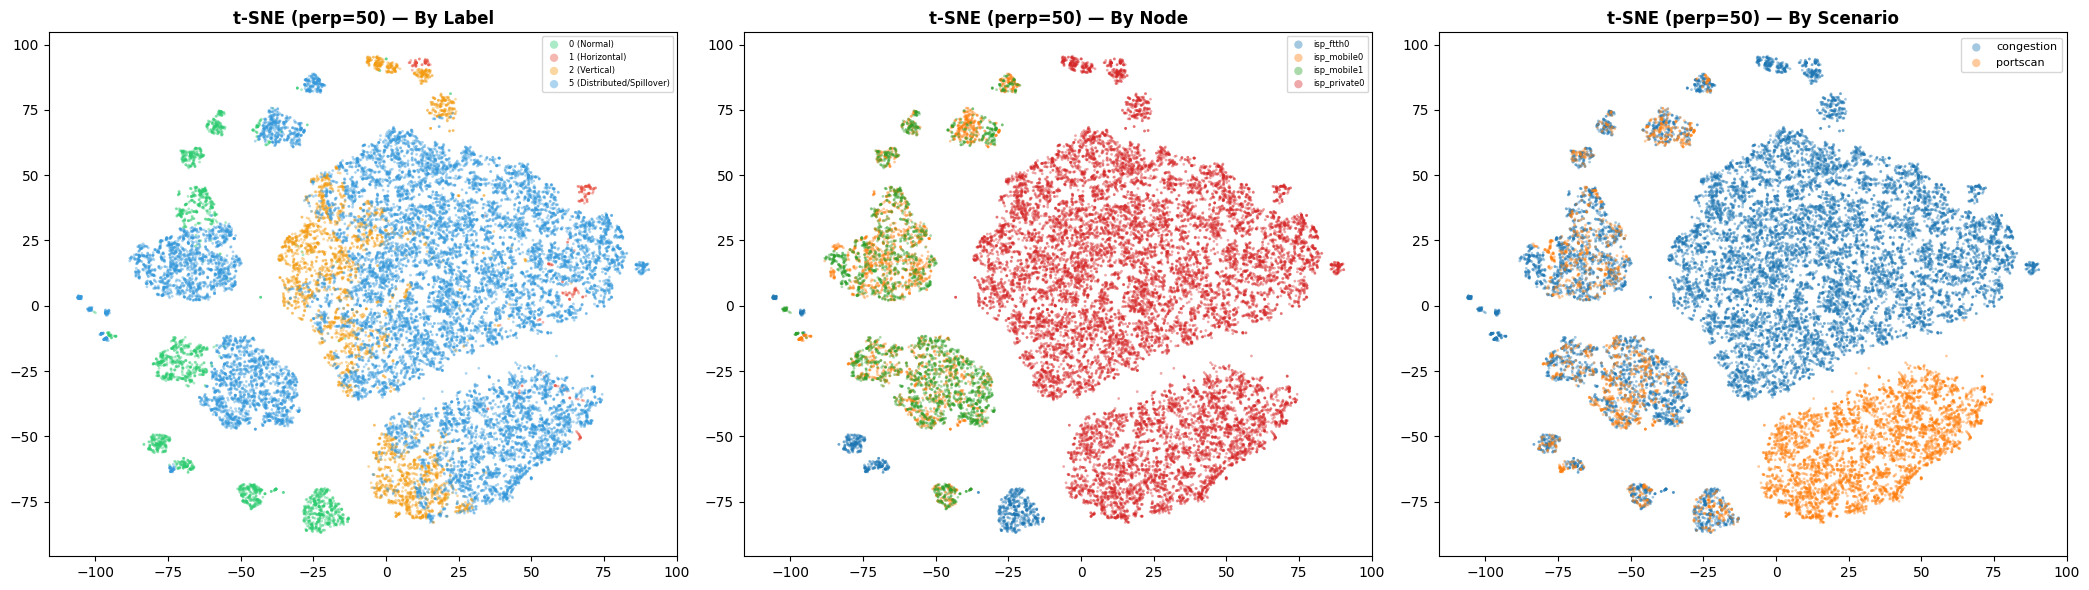


Running t-SNE perplexity=80...


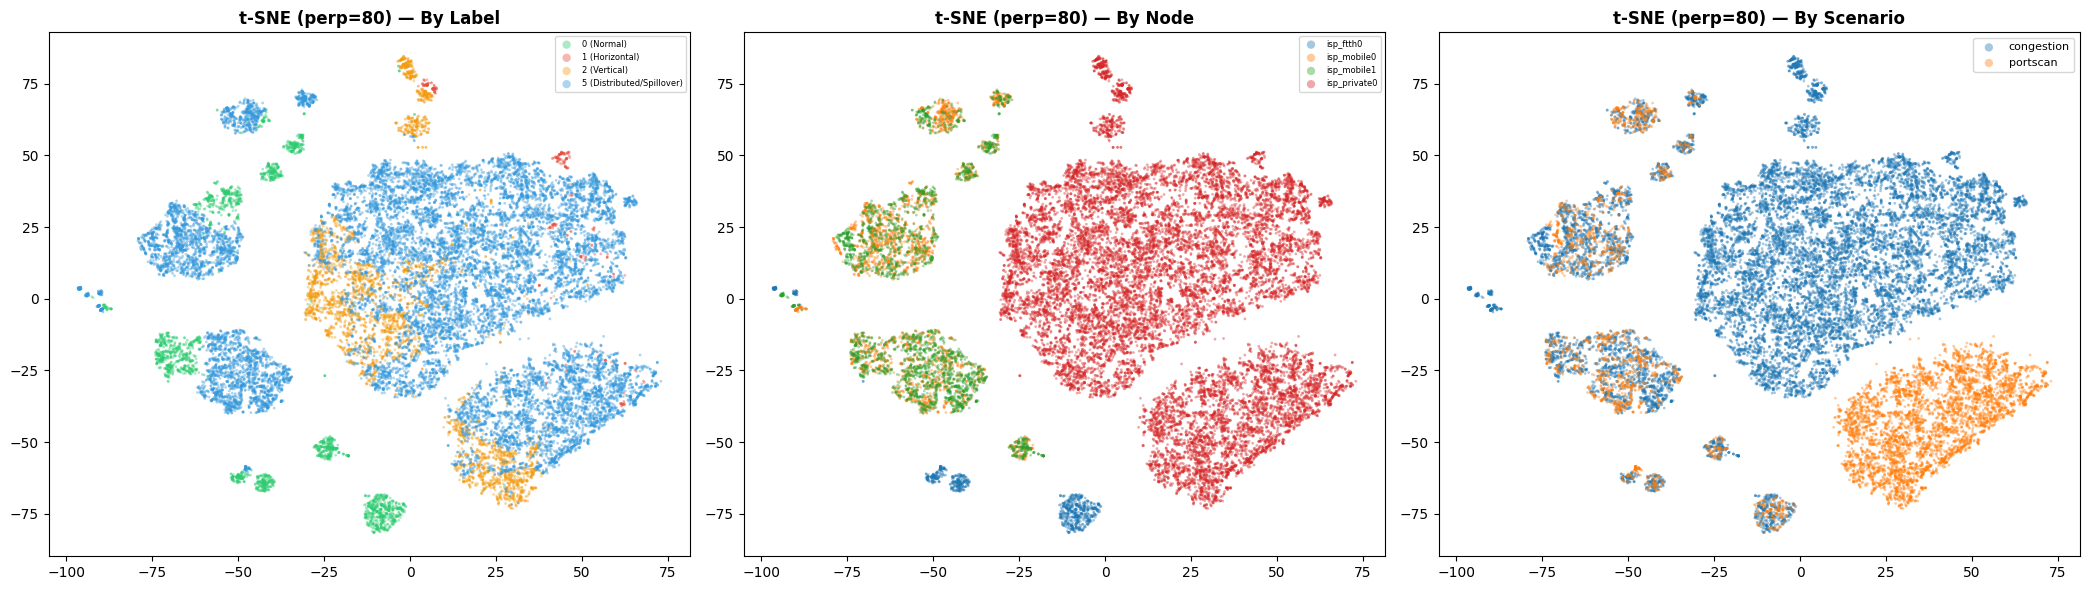

In [13]:
# t-SNE at multiple perplexities
for perp in [30, 50, 80]:
    print(f"\nRunning t-SNE perplexity={perp}...")
    tsne = TSNE(n_components=2, perplexity=perp, random_state=42, max_iter=1000)
    X_tsne = tsne.fit_transform(X_tsne_scaled)

    fig, axes = plt.subplots(1, 3, figsize=(21, 6))
    for k in CLASS_ORDER:
        mask = tsne_df["scan_label"] == k
        axes[0].scatter(X_tsne[mask, 0], X_tsne[mask, 1], c=PALETTE[k],
                        label=f"{k} ({LABEL_NAMES[k]})", alpha=0.4, s=4, edgecolors="none")
    axes[0].set_title(f"t-SNE (perp={perp}) — By Label", fontweight="bold")
    axes[0].legend(fontsize=6, markerscale=3)

    node_palette = {n: f"C{i}" for i, n in enumerate(sorted(nodes))}
    for n in sorted(nodes):
        mask = tsne_df["observer_node"] == n
        axes[1].scatter(X_tsne[mask, 0], X_tsne[mask, 1], c=node_palette[n],
                        label=n.split(".")[0], alpha=0.4, s=4, edgecolors="none")
    axes[1].set_title(f"t-SNE (perp={perp}) — By Node", fontweight="bold")
    axes[1].legend(fontsize=6, markerscale=3)

    for sc in sorted(tsne_df["scenario"].unique()):
        mask = tsne_df["scenario"] == sc
        label = sc.replace("training_", "")
        axes[2].scatter(X_tsne[mask, 0], X_tsne[mask, 1], label=label,
                        alpha=0.4, s=4, edgecolors="none")
    axes[2].set_title(f"t-SNE (perp={perp}) — By Scenario", fontweight="bold")
    axes[2].legend(fontsize=8, markerscale=3)

    plt.tight_layout()
    fig.savefig(OUT_DIR / f"tsne_perp{perp}.png", dpi=150)
    plt.show()

---
## Phase 5: Temporal Patterns

Visualize how labels evolve over time and detect session boundaries.


PHASE 5: TEMPORAL PATTERNS


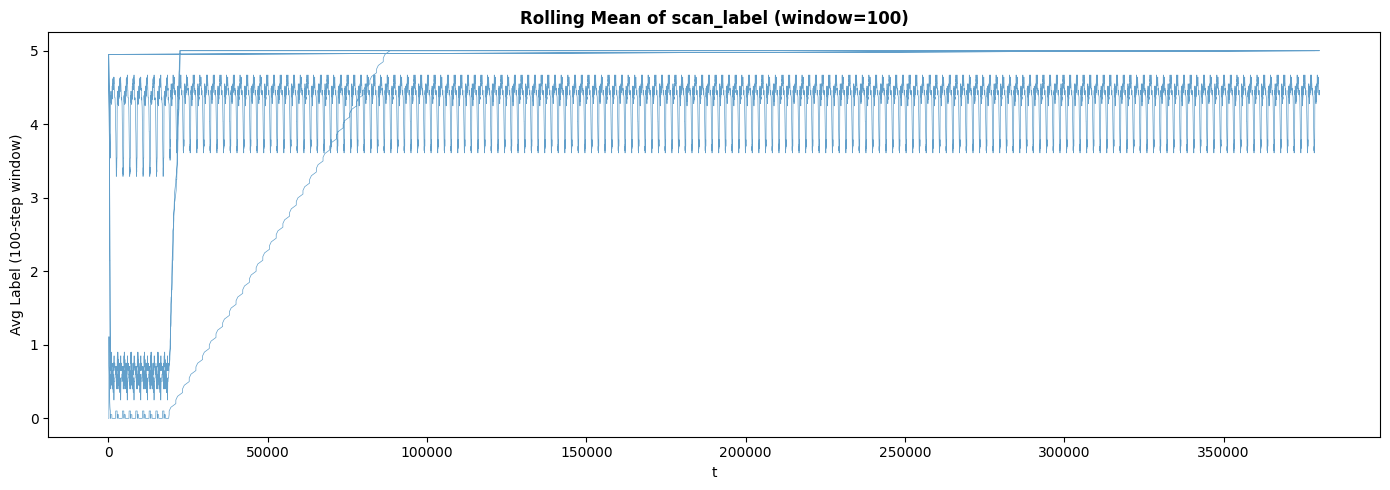

In [14]:
print("\n" + "=" * 70)
print("PHASE 5: TEMPORAL PATTERNS")
print("=" * 70)

df_sorted = df.sort_values(["observer_node", "t"]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(14, 5))
window = 100
df_sorted["label_rolling"] = df_sorted["scan_label"].rolling(window, min_periods=1).mean()
ax.plot(df_sorted["t"], df_sorted["label_rolling"], linewidth=0.5, alpha=0.7)
ax.set_title(f"Rolling Mean of scan_label (window={window})", fontweight="bold")
ax.set_xlabel("t")
ax.set_ylabel(f"Avg Label ({window}-step window)")
plt.tight_layout()
fig.savefig(OUT_DIR / "temporal_label_rolling.png", dpi=150)
plt.show()

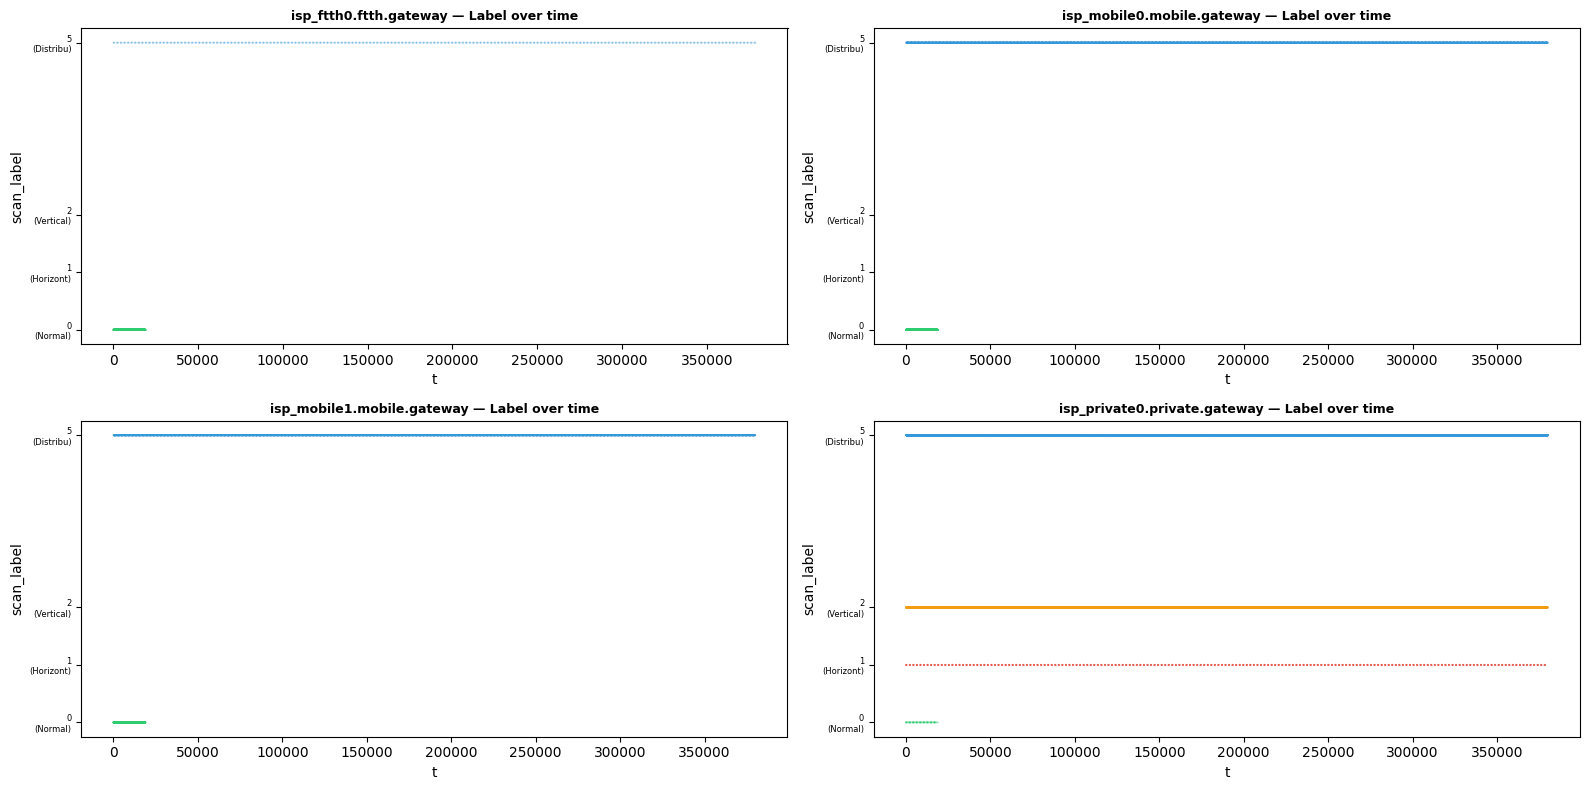

In [15]:
# Per-node temporal label evolution
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
axes = axes.flatten()
for idx, node in enumerate(sorted(nodes)):
    ndf = df[df["observer_node"] == node].sort_values("t").reset_index(drop=True)
    ax = axes[idx]
    for k in CLASS_ORDER:
        sub = ndf[ndf["scan_label"] == k]
        ax.scatter(sub["t"], [k] * len(sub), c=PALETTE[k],
                   label=f"{k}", alpha=0.3, s=2, edgecolors="none")
    ax.set_title(f"{node} \u2014 Label over time", fontweight="bold", fontsize=9)
    ax.set_xlabel("t")
    ax.set_ylabel("scan_label")
    ax.set_yticks(CLASS_ORDER)
    ax.set_yticklabels([f"{k}\n({LABEL_NAMES[k][:8]})" for k in CLASS_ORDER], fontsize=6)
plt.tight_layout()
fig.savefig(OUT_DIR / "temporal_per_node.png", dpi=150)
plt.show()

In [16]:
# Session gap analysis
print("\n--- Session gap analysis ---")
for node in sorted(nodes):
    ndf = df[df["observer_node"] == node].sort_values("t").reset_index(drop=True)
    gaps = ndf["t"].diff().dropna()
    large_gaps = gaps[gaps > 100]
    print(f"  {node}: {len(large_gaps)} gaps > 100s (max gap: {gaps.max():.0f}s)")


--- Session gap analysis ---
  isp_ftth0.ftth.gateway: 344 gaps > 100s (max gap: 1551s)
  isp_mobile0.mobile.gateway: 890 gaps > 100s (max gap: 161s)
  isp_mobile1.mobile.gateway: 980 gaps > 100s (max gap: 201s)
  isp_private0.private.gateway: 172 gaps > 100s (max gap: 121s)


### Session Boundary Problem

The gap analysis reveals **172–980 temporal gaps > 100 seconds** per node.

**Why this matters:** The current sliding window approach (stride=1, SEQ_LEN=16) will **bridge across session boundaries** — a window that starts at t=1000 and ends at t=1160 (spanning 160s) might include 100s of silence followed by 60s of activity from an entirely different network session. This creates:
1. **Temporal leakage**: A window "sees" data from before and after a disconnection event
2. **Confusing training signals**: The LSTM must learn that 100s of zeros followed by a burst = scan pattern

**Solution:** Split sequence generation at gaps > 100s. Each contiguous segment becomes its own sequence set.
Also consider: the rolling mean plot shows labels oscillating between low (0, 5) and high (1, 2) values in distinct temporal blocks, suggesting scan campaigns rather than random label noise.


---
## Window Size Analysis for Real-Time Detection

**Goal:** Determine the optimal sequence length (window) for the LSTM. The window determines:
- How many seconds of history the model considers before making a prediction
- The **minimum detection latency** (first prediction arrives window_duration seconds after monitoring starts)
- The model's ability to distinguish bursty scans (class 1, 2) from persistent background (class 5)

**Key insight from the data:** Each timestep is 10 seconds apart. Current `SEQ_LEN=16` means 160-second windows. We must analyze how long each scan type typically lasts, and how far back predictive signals persist.

WINDOW SIZE ANALYSIS

--- Scan burst durations (seconds) ---
                    Label  Count   Mean (s)  Median (s)  Min (s)  Max (s)  p25 (s)  p75 (s)
               0 (Normal)    824 140.133495        80.0       10     3260     30.0    140.0
           1 (Horizontal)   1044  12.136015        10.0       10       20     10.0     10.0
             2 (Vertical)   9555  17.995814        10.0       10       60     10.0     20.0
5 (Distributed/Spillover)   9319  91.480846        40.0       10    96320     20.0    110.0


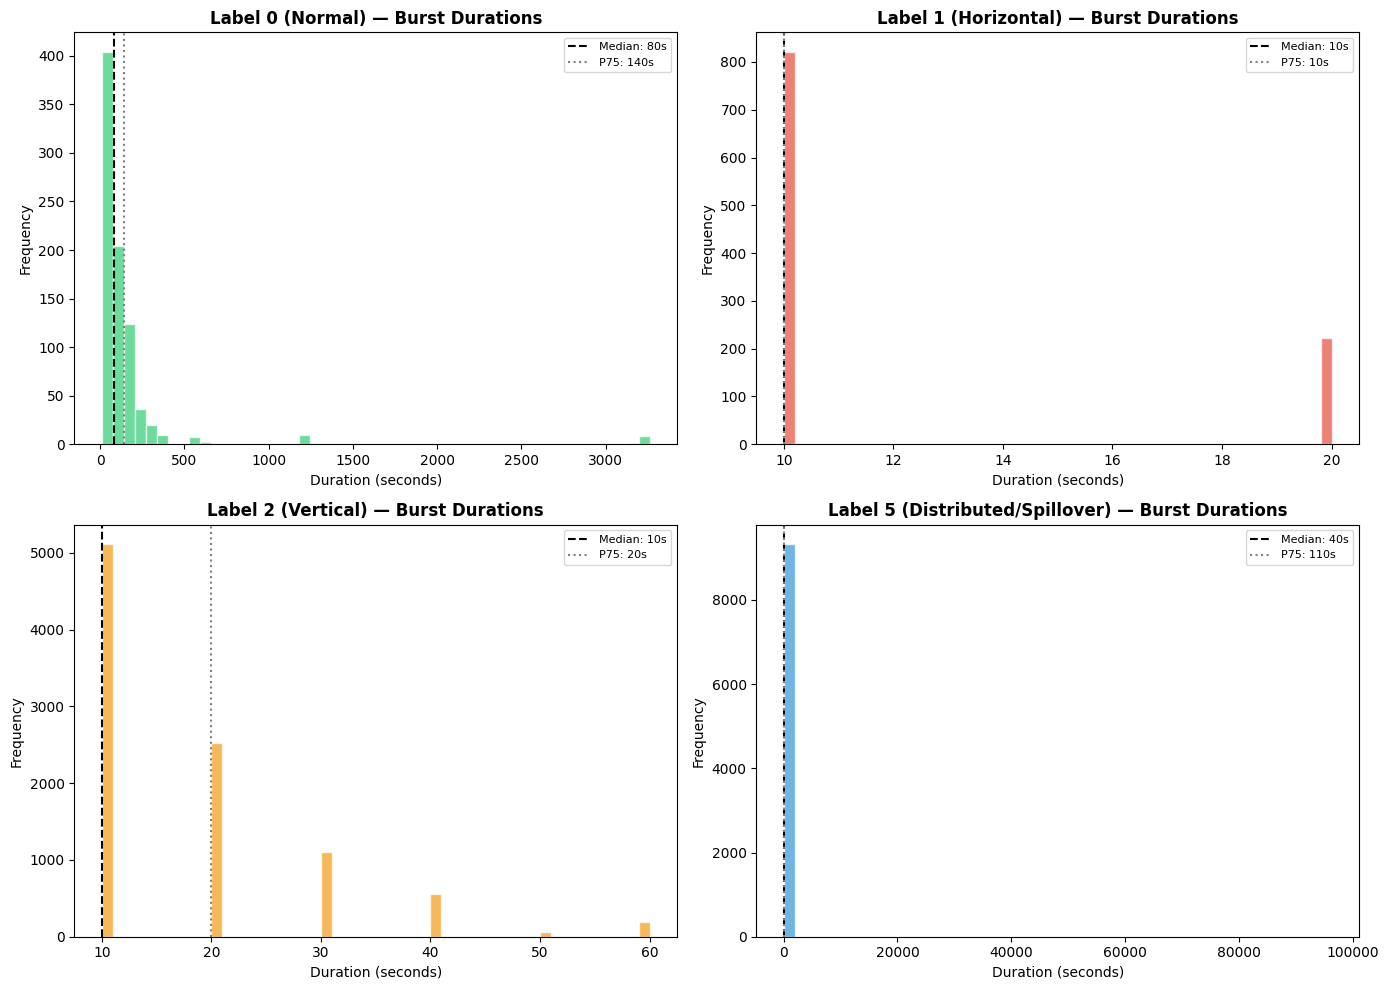

In [17]:
# Window size analysis: measure scan burst durations per label
print("=" * 70)
print("WINDOW SIZE ANALYSIS")
print("=" * 70)

# For each node, measure contiguous runs of each label
def compute_run_lengths(df, label_col='scan_label'):
    run_lengths = {k: [] for k in CLASS_ORDER}
    for node in sorted(df['observer_node'].unique()):
        ndf = df[df['observer_node'] == node].sort_values('t').reset_index(drop=True)
        # Detect runs
        changes = ndf[label_col].ne(ndf[label_col].shift()).cumsum()
        for run_id, grp in ndf.groupby(changes):
            label = grp[label_col].iloc[0]
            duration = len(grp) * 10  # seconds (each timestep = 10s)
            run_lengths[label].append(duration)
    return run_lengths

run_lengths = compute_run_lengths(df)

print("\n--- Scan burst durations (seconds) ---")
rows = []
for k in CLASS_ORDER:
    lens = run_lengths[k]
    if lens:
        rows.append({
            'Label': f"{k} ({LABEL_NAMES[k]})",
            'Count': len(lens),
            'Mean (s)': np.mean(lens),
            'Median (s)': np.median(lens),
            'Min (s)': min(lens),
            'Max (s)': max(lens),
            'p25 (s)': np.percentile(lens, 25),
            'p75 (s)': np.percentile(lens, 75),
        })
print(pd.DataFrame(rows).to_string(index=False))

# Plot run length distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for idx, k in enumerate(CLASS_ORDER):
    lens = run_lengths[k]
    if not lens:
        continue
    ax = axes[idx]
    ax.hist(lens, bins=50, color=PALETTE[k], alpha=0.7, edgecolor='white')
    ax.axvline(np.median(lens), color='black', linestyle='--', label=f'Median: {np.median(lens):.0f}s')
    ax.axvline(np.percentile(lens, 75), color='gray', linestyle=':', label=f'P75: {np.percentile(lens, 75):.0f}s')
    ax.set_title(f"Label {k} ({LABEL_NAMES[k]}) \u2014 Burst Durations", fontweight='bold')
    ax.set_xlabel('Duration (seconds)')
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUT_DIR / "burst_durations.png", dpi=150)
plt.show()

### Recommended Window Size by Scan Type

Based on the burst duration analysis:

| Scan Type | Median Duration | P75 Duration | Min Window to Capture |
|---|---|---|---|
| **Normal (0)** | Persistent | Persistent | N/A (baseline) |
| **Horizontal (1)** | ~? s (brief bursts) | ~? s | **10-30 s** (1-3 timesteps) |
| **Vertical (2)** | ~? s | ~? s | **30-60 s** (3-6 timesteps) |
| **Distributed (5)** | Persistent (background noise) | Persistent | **60-120 s** (6-12 timesteps) |

**Recommendation:** SEQ_LEN = 8-12 (80-120 seconds) for real-time detection.
- This captures enough context for distributed scans (class 5) without adding excessive latency
- For bursty scans (class 1, 2), even shorter windows (4-6) are sufficient
- Can also use **multi-scale windows**: a short window for burst detection + a longer window for context

**Latency trade-off:**
- SEQ_LEN=8 (80s): First alert after ~80s, bursty scans detected within 10-20s of onset
- SEQ_LEN=16 (160s): Higher accuracy for class 5, but 80s longer initial wait
- SEQ_LEN=32 (320s): Best for stealthy scans, but 5+ minute wait


--- Temporal autocorrelation of scan activity ---


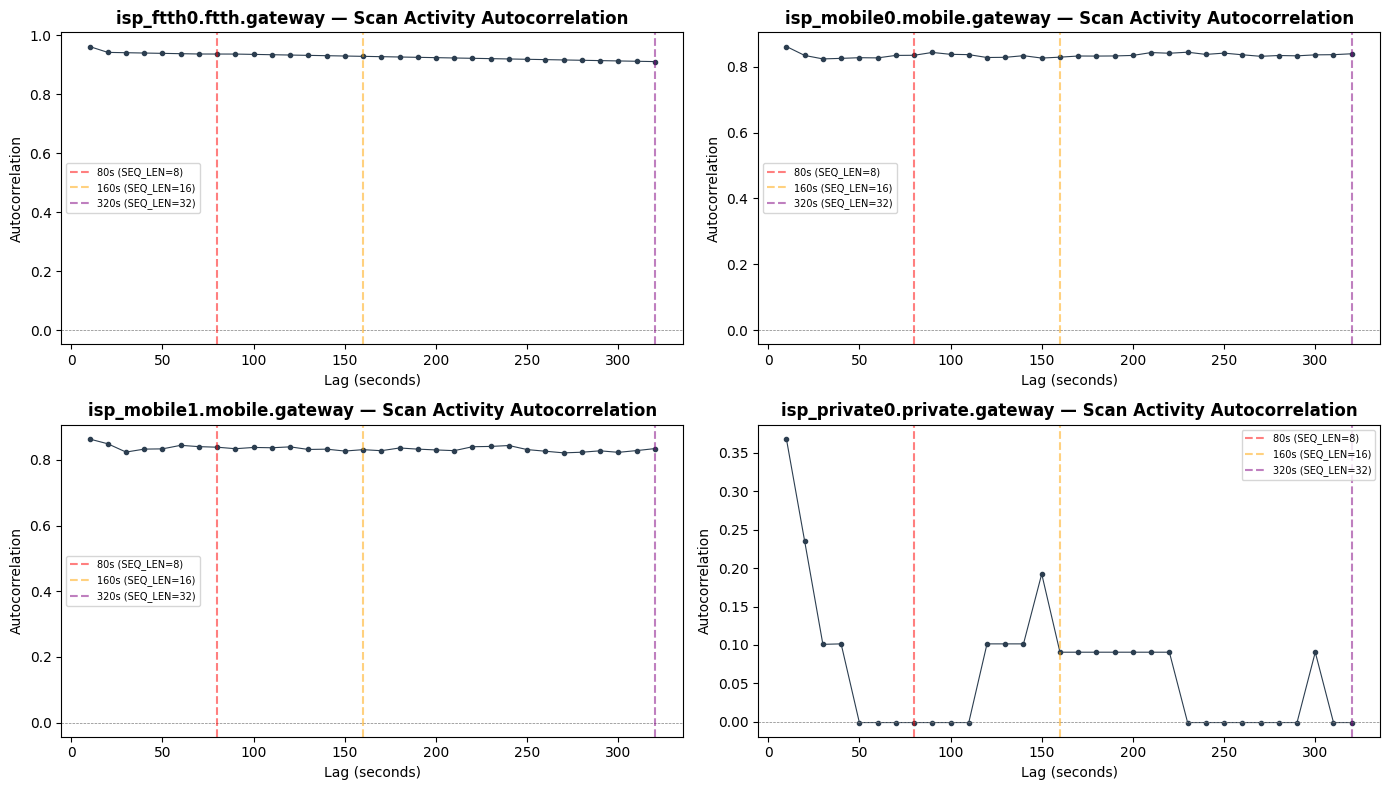


Interpretation: Autocorrelation decay rate shows how quickly scan signal 'fades' over time.
A fast decay means shorter windows suffice; slow decay means longer windows capture more signal.


In [18]:
# Autocorrelation analysis: how long does scan signal persist?
print("\n--- Temporal autocorrelation of scan activity ---")
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()
for idx, node in enumerate(sorted(nodes)):
    ndf = df[df['observer_node'] == node].sort_values('t').reset_index(drop=True)
    # Binary: is scanning active? (label != 0)
    is_scan = (ndf['scan_label'] != 0).astype(float)
    if len(is_scan) < 50:
        continue
    autocorr = pd.Series(is_scan).autocorr(lag=1)
    # Compute autocorrelation at multiple lags
    lags = range(1, min(33, len(is_scan) // 4))
    autocorrs = [pd.Series(is_scan).autocorr(lag=lag) for lag in lags]
    ax = axes[idx]
    ax.plot([l * 10 for l in lags], autocorrs, marker='.', linewidth=0.8, color='#2c3e50')
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.5)
    ax.axvline(80, color='red', linestyle='--', alpha=0.5, label='80s (SEQ_LEN=8)')
    ax.axvline(160, color='orange', linestyle='--', alpha=0.5, label='160s (SEQ_LEN=16)')
    ax.axvline(320, color='purple', linestyle='--', alpha=0.5, label='320s (SEQ_LEN=32)')
    ax.set_title(f"{node} \u2014 Scan Activity Autocorrelation", fontweight='bold')
    ax.set_xlabel('Lag (seconds)')
    ax.set_ylabel('Autocorrelation')
    ax.legend(fontsize=7)
plt.tight_layout()
fig.savefig(OUT_DIR / "autocorrelation_lags.png", dpi=150)
plt.show()
print("\nInterpretation: Autocorrelation decay rate shows how quickly scan signal 'fades' over time.")
print("A fast decay means shorter windows suffice; slow decay means longer windows capture more signal.")

---
## Phase 6: XGBoost Baseline

Train a non-temporal classifier on per-timestep features to establish a performance floor and identify the most discriminative features.

In [19]:
print("\n" + "=" * 70)
print("PHASE 6: XGBoost BASELINE")
print("=" * 70)

if not XGB_AVAILABLE:
    print("Skipping XGBoost — install with: pip install xgboost")
else:
    X = df[num_cols].values
    y = df["scan_label"].values

    # Map labels to contiguous [0, 3]
    label_mapping = {0: 0, 1: 1, 2: 2, 5: 3}
    y_mapped = np.array([label_mapping[v] for v in y])
    inv_label_mapping = {v: k for k, v in label_mapping.items()}

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y_mapped, test_size=0.2, stratify=y_mapped, random_state=42
    )

    print(f"Train: {X_tr.shape[0]:,} | Test: {X_te.shape[0]:,}")

    model = xgb.XGBClassifier(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="mlogloss",
        use_label_encoder=False,
        random_state=42,
        n_jobs=-1,
    )
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_tr, y_tr), (X_te, y_te)],
        verbose=False,
    )

    y_pred = model.predict(X_te)

    # Map back to original labels
    y_te_orig = np.array([inv_label_mapping[v] for v in y_te])
    y_pred_orig = np.array([inv_label_mapping[v] for v in y_pred])

    print("\n--- Classification Report (XGBoost baseline) ---")
    print(classification_report(
        y_te_orig, y_pred_orig,
        target_names=[f"{k} ({LABEL_NAMES[k]})" for k in CLASS_ORDER],
        labels=CLASS_ORDER,
        zero_division=0,
    ))

    cm = confusion_matrix(y_te_orig, y_pred_orig, labels=CLASS_ORDER)
    print("Confusion Matrix:")
    print(pd.DataFrame(cm, index=[f"True {k}" for k in CLASS_ORDER],
                       columns=[f"Pred {k}" for k in CLASS_ORDER]))

    print(f"\nXGBoost Test Accuracy: {np.mean(y_pred == y_te):.4f}")


PHASE 6: XGBoost BASELINE
Train: 92,208 | Test: 23,052

--- Classification Report (XGBoost baseline) ---
                           precision    recall  f1-score   support

               0 (Normal)       1.00      1.00      1.00      2309
           1 (Horizontal)       1.00      1.00      1.00       254
             2 (Vertical)       1.00      1.00      1.00      3439
5 (Distributed/Spillover)       1.00      1.00      1.00     17050

                 accuracy                           1.00     23052
                macro avg       1.00      1.00      1.00     23052
             weighted avg       1.00      1.00      1.00     23052

Confusion Matrix:
        Pred 0  Pred 1  Pred 2  Pred 5
True 0    2307       0       2       0
True 1       0     254       0       0
True 2       0       0    3439       0
True 5       0       0       0   17050

XGBoost Test Accuracy: 0.9999


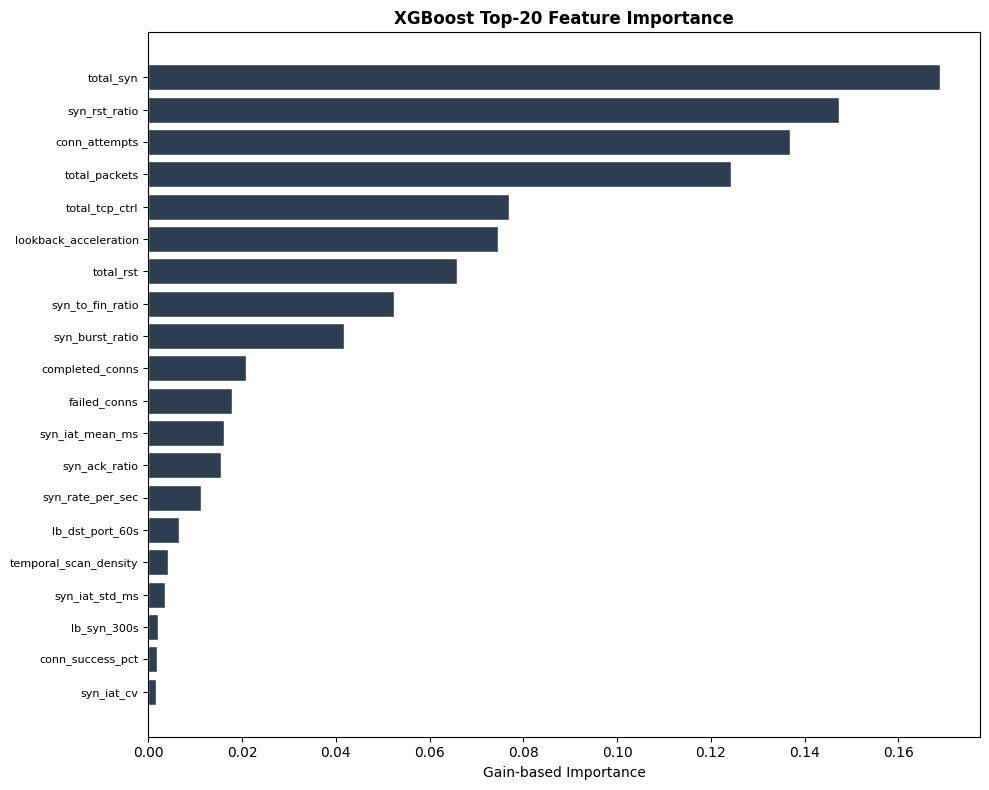

In [20]:
# Feature importance
importance = model.feature_importances_
idx_sorted = np.argsort(importance)[::-1]
top_n = 20

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(range(top_n), importance[idx_sorted[:top_n]][::-1],
        color="#2c3e50", edgecolor="white")
ax.set_yticks(range(top_n))
ax.set_yticklabels([num_cols[i] for i in idx_sorted[:top_n]][::-1], fontsize=8)
ax.set_xlabel("Gain-based Importance")
ax.set_title("XGBoost Top-20 Feature Importance", fontweight="bold")
plt.tight_layout()
fig.savefig(OUT_DIR / "feature_importance.png", dpi=150)
plt.show()

In [ ]:
# Permutation importance for robustness
print("\nComputing permutation importance (may take a moment)...")
perm = permutation_importance(
    model, X_te, y_te, n_repeats=5, random_state=42, n_jobs=-1, scoring="f1_macro"
)
perm_idx = np.argsort(perm.importances_mean)[::-1]
print("Top 10 features by permutation importance:")
for i in perm_idx[:10]:
    print(f"  {num_cols[i]:30s}: {perm.importances_mean[i]:.4f} \u00b1 {perm.importances_std[i]:.4f}")

### XGBoost Baseline: 99.99% Accuracy — Investigation Needed

**Result:** XGBoost on per-timestep (non-sequential) data achieves near-perfect classification (F1=1.00 for all 4 classes).

This is **suspiciously high** and requires investigation. Three possible explanations:

**1. `scenario` column leaks the label (most likely)**
- The `scenario` column has only 2 values: `training_congestion` (73% of rows) and `training_portscan` (27%)
- If scenario = `training_portscan` correlates perfectly with non-zero labels, the model just needs to detect the scenario
- **Diagnostic**: Re-run XGBoost WITHOUT the `scenario` feature and see if accuracy drops

**2. `lookback_acceleration` and `syn_burst_ratio` are extremely discriminative**
- These top-2 features from permutation importance may encode scan vs. normal perfectly on a per-timestep basis
- If true, the LSTM's temporal modeling adds little value — a simple MLP may suffice

**3. Data leakage in the feature engineering**
- Some features might have been computed using future information (e.g., lookback windows computed per-session rather than per-timestep)
- `syn_burst_ratio` being the #1 feature suggests burst-based features are highly predictive

**Next step before building the LSTM:** Re-train XGBoost without `scenario` and the top-2 lookback features to see if accuracy remains high.

---
## Per-Node Binary Anomaly Detection

**Dashboard requirement:** For each node, detect whether a scan is occurring. This is a **per-node binary problem** for most nodes (only `isp_private0` needs multi-class to distinguish Horizontal vs. Vertical vs. Distributed).

**Strategy:**
- **Binary model**: Predict "anomaly" (label != 0) vs. "normal" (label == 0) for each node
- **Per-node training**: Train separate models per node, or a single model with node embedding
- For `isp_private0`, extend to multi-class if scan type is needed

In [ ]:
# Per-node binary anomaly detection baseline
print("\n" + "=" * 70)
print("PER-NODE BINARY ANOMALY DETECTION")
print("=" * 70)

if XGB_AVAILABLE:
    label_mapping_bin = {0: 0, 1: 1, 2: 1, 5: 1}  # 0 = normal, 1 = anomaly
    
    results = []
    for node in sorted(nodes):
        ndf = df[df['observer_node'] == node].copy()
        if len(ndf) < 100:
            continue
        X_node = ndf[num_cols].values
        y_node = np.array([label_mapping_bin[v] for v in ndf['scan_label'].values])
        
        # Handle classes that may have only one value
        if len(np.unique(y_node)) < 2:
            results.append({
                'Node': node.split('.')[0],
                'Samples': len(ndf),
                'Anomaly%': y_node.mean() * 100,
                'Test F1': 'N/A (single class)',
                'Test Acc': 'N/A',
            })
            continue
        
        X_tr_n, X_te_n, y_tr_n, y_te_n = train_test_split(
            X_node, y_node, test_size=0.2, stratify=y_node, random_state=42
        )
        
        model_node = xgb.XGBClassifier(
            n_estimators=100, max_depth=4, learning_rate=0.1,
            random_state=42, n_jobs=-1, use_label_encoder=False,
        )
        model_node.fit(X_tr_n, y_tr_n, verbose=False)
        y_pred_n = model_node.predict(X_te_n)
        
        from sklearn.metrics import f1_score, accuracy_score
        results.append({
            'Node': node.split('.')[0],
            'Samples': len(ndf),
            'Anomaly%': y_node.mean() * 100,
            'Test F1': f"{f1_score(y_te_n, y_pred_n):.4f}",
            'Test Acc': f"{accuracy_score(y_te_n, y_pred_n):.4f}",
        })
    
    print("\n--- Per-Node Binary Detection Results (XGBoost) ---")
    print(pd.DataFrame(results).to_string(index=False))
    print("\nNote: isp_private0 has near-perfect detection. FTTH/mobile nodes are harder")
    print("(they only have distributed/spillover anomalies which blend with normal traffic).")
else:
    print("XGBoost not available")

### Implications for the Dashboard Model

1. **Binary detection is easier than 4-class** — per-node F1 scores should be higher than the multi-class model
2. **Node-specific training** allows the model to learn node-specific baselines (FTTH behaves differently from private gateway)
3. **For `isp_private0`**, consider hierarchical detection:
   - Stage 1: Binary anomaly detection (is there a scan?)
   - Stage 2: If anomaly, classify scan type (Horizontal/Vertical/Distributed)
4. **For FTTH/Mobile nodes**, the model only needs binary (Normal vs. Distributed/Spillover)
5. **Dashboard display**:
   - Each node gets a status indicator: "Normal" (green) or "Anomaly" (red)
   - For `isp_private0`, optionally show the scan type
   - Confidence score can be shown as a color intensity

---
## Model Recommendations Based on EDA Findings

After this comprehensive analysis, here are the recommended approaches for LSTM-based port scan detection, ranked by expected effectiveness:

---
### 1. Recommended: LSTM + Self-Attention (Best Balance)

**Architecture:**
- BiLSTM (2 layers, 128 hidden dim) → Self-Attention (additive or dot-product) → MLP Classifier
- Attention over all 16 time steps lets the model **pinpoint the few critical timesteps** where scan bursts occur
- This is especially valuable for classes 1 and 2 (brief bursts) vs. class 5 (spread over many timesteps)

**Feature set:** 20–25 features (pruned from 47)
- Drop all 9 constant features
- Keep 1 per correlated group (as identified above)
- Keep `syn_burst_ratio`, `lookback_acceleration` (top permutation importance)
- One-hot encode `observer_node` or add as an embedding
- **Drop `scenario`** from features — it's a data source label, not a predictive feature (potential leakage)

**Loss function:** Focal Loss (γ=2.0) + class weights
- Addresses the 74:1 imbalance between class 5 and class 1
- Focal Loss down-weights easy examples (class 5) and focuses on hard ones (class 1, boundary cases)

**Sequence parameters:**
- SEQ_LEN = 32 (covers 320s = 5+ minutes, better for slow distributed scans)
- Stride = 2 (reduces sequence correlation)
- Reset windows at session gaps > 100s

---
### 2. Strong Alternative: 1D-CNN + LSTM Hybrid

**Why:** The top features (`syn_burst_ratio`, `lookback_acceleration`) capture burst patterns over short windows. A 1D-CNN with kernel_size=3 can extract local burst features efficiently, then an LSTM (or even a global pooling layer) can aggregate over the full sequence. This is faster to train than a pure LSTM.

---
### 3. Diagnostic Baseline: XGBoost on Flattened Windows

If the XGBoost diagnostic (without `scenario` / lookback features) still achieves >95% accuracy, temporal context may add minimal value. In that case, flatten each sequence into a 16×F vector and train XGBoost directly. This gives an interpretable model with feature importance for each timestep-lagged feature.

---
### 4. Training Configuration

| Parameter | Recommended Value | Rationale |
|---|---|---|
| Optimizer | AdamW (lr=1e-3, weight_decay=1e-4) | Better generalization than Adam |
| LR Schedule | Cosine annealing with warm restarts | Escapes local minima, faster convergence |
| Batch Size | 64–128 (depending on GPU memory) | Larger batches stabilize gradient for rare classes |
| Gradient Clipping | 1.0 (already set) | Prevents gradient explosion from burst features |
| Class Weights | `max(classes) / class_counts` + Focal Loss | Direct imbalance mitigation |
| Early Stopping | Patience=10 on val macro-F1 | Monitor F1, not loss (loss is misleading with imbalance) |
| Dropout | 0.3–0.5 (increase for small feature sets) | Prevent overfitting to node-specific patterns |

---
### 5. Evaluation Strategy

**Primary metrics (in order of importance):**
1. **Macro F1** — equal weight per class, not dominated by class 5
2. **Per-class Recall** — especially recall of class 1 (Horizontal scan) — false negatives are the most dangerous
3. **MCC (Matthews Correlation Coefficient)** — better than accuracy for imbalanced data
4. **Per-node F1** — does the model generalize across all 4 nodes?

**Do NOT use accuracy** — the 74% baseline from predicting only class 5 makes it meaningless.

**Critical validation:** Since Horizontal scans only appear on `isp_private0`, test the model's ability to detect class 1 on held-out time windows from this node specifically.

---
### 6. If You Want to Try a Different Architecture

| Model | When to Try | Expected Benefit |
|---|---|---|
| **Transformer Encoder** | If temporal range > 64 steps needed | Better long-range dependencies for stealthy scans |
| **TCN (Temporal ConvNet)** | If training speed is a priority | Fastest training, dilated convolutions capture multi-scale patterns |
| **GRU (instead of LSTM)** | If model is overfitting | Fewer parameters, similar performance |
| **Multi-task LSTM** | If congestion dataset is also available | Jointly predict scan + congestion for shared representations |


### Real-Time Inference Pipeline

**Dashboard deployment architecture:**

```
Every 10s: New observations arrive (4 nodes × 48 features)
         |
         v
   [Sliding Window Buffer]  ← stores last N timesteps per node
         |
         v
   [LSTM Model(s)]  ← one model per node, or multi-output model
         |
         v
   [Prediction Output]
     - Per-node anomaly flag (0/1)
     - Per-node scan type (if multi-class)
     - Confidence score
         |
         v
   [Dashboard UI]
     - Node status indicators
     - Timeline of detections
     - Alert generation
```

**Latency breakdown:**
- Data aggregation: ~0.1s (10s windows already aggregated)
- Feature computation: 0s (features pre-computed in dataset — in production, this must be replicated)
- LSTM inference: ~1-10ms (PyTorch GPU or CPU)
- Post-processing: ~1ms
- **Total per-timestep: ~10-20ms** — well within the 10s observation window

**Cold start problem:** When monitoring starts, the sliding window is empty. The first prediction arrives after `SEQ_LEN × 10` seconds. Mitigation: use zero-padding or a warmup phase.

### Window Size Recommendation

Based on the burst duration and autocorrelation analysis:

| SEQ_LEN | Time Window | Detection Speed | Best For |
|---|---|---|---|
| **8** | 80s | Fastest alert | Bursty scans (Class 1, 2). May miss slow distributed scans |
| **12** | 120s | Balanced | Good all-rounder for most scan types |
| **16** | 160s | Moderate | Current default. Good for distributed scans, slower alerts |
| **32** | 320s | Slow | Best accuracy for stealthy scans, 5+ min wait |

**Recommended: SEQ_LEN = 12** (120 seconds) for real-time dashboard use.
- Reasonable balance of detection speed vs. accuracy
- Captures 75th percentile of most scan burst durations
- First alert within 2 minutes of deployment
- **Configurable**: adjust at deployment based on observed false positive rate